<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QPCA_IntrusionDetection_Salem2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QPCA features for intrusion detection under NISQ constraints: Salem et al. (2026) step by step

This notebook re-implements, runs and checks the experiments of

> Murilo Salem, Daniel Pontes, Luísa Böhm, Henrique dos Reis, Karen Satie Ono and Anderson Priebe Ferrugem,
> "Hybrid Quantum-Classical Intrusion Detection with Quantum Feature Representations under NISQ Constraints",
> *46º Congresso da Sociedade Brasileira de Computação (CSBC 2026) / 1º Simpósio Brasileiro de Computação e Comunicação Quânticas (SBCCQ 2026)*, Gramado/RS, 2026.
> Universidade Federal de Pelotas. DOI 10.5753/sbccq.2026.23307

The paper asks a narrow question: **can a quantum feature stage (QPCA) give a classical intrusion-detection classifier a better input than plain PCA, without
claiming quantum superiority?** It compares PCA→{LR, SVM, RF}, QPCA→{LR, SVM, RF} and a QPCA→VQC arm on CIC-IDS2017 and NSL-KDD, in a small
("nisq") and a larger ("scaled") data regime, with paired seeds, Wilcoxon-Holm tests, bootstrap intervals and a cost analysis. The paper's code is announced
but not released (the repository URL is a placeholder), so everything below is written from the nine-page description.

**What the notebook does.** It downloads both public datasets, builds the explicit train/validation/test splits for the paper's seeds, trains the seven
pipelines of the paper's Table 3 on exactly the same inputs, re-draws Table 3, the paired PCA-versus-QPCA contrasts of Figure 1 with Wilcoxon-Holm
statistics and bootstrap intervals, and the cost-performance picture of Figure 2, and finishes with a claim-by-claim comparison with the paper. The two
quantum circuits (the QPCA feature circuit and the VQC) are drawn from the Qiskit objects that define them, and their fast simulation is asserted to
agree with Qiskit's own statevector simulation. An extra section (not in the paper) pushes the QPCA circuit through shot noise and the calibrated
noise model of a fake IBM device.

**How to run it.** Open it in Colab (badge above), choose a **CPU** runtime and use *Runtime -> Run all*. The first cell installs pinned versions of Qiskit
(a session restart may be requested; if so, run all cells again). The one-off download is about 0.8 GB (the eight daily CIC-IDS2017 CSV files are read in
chunks, sampled and deleted again; NSL-KDD is 20 MB) and takes a few minutes. With `FAST_MODE = True` (3 seeds, smaller scaled budget, shorter
optimiser) the whole notebook takes about 5 minutes after the download; with `FAST_MODE = False` (the paper's 5 + 5 seeds, the setting of the stored outputs) it takes about 25 minutes on a laptop CPU. Both
datasets are public; a Hugging Face token is **not** needed, but if a mirror ever becomes gated, store your own token in Colab *Secrets* under the name
`HF_TOKEN` (the notebook reads it from there or from the environment, never from the notebook text).

**What you get at the end.** Executed tables and figures, and a table that puts every number the paper reports next to the number obtained here, with a verdict
("reproduced" = within 0.02, otherwise "not reached" / "exceeded" with the gap, or "cannot be checked").

## The paper in one page

**Problem.** Decide for each network connection or flow whether it is benign or an attack (binary), and find out *when* a quantum representation stage helps a
classical classifier, "under NISQ constraints": simulator-only execution, few qubits, shallow circuits, small sample budgets and explicit cost accounting. The
paper explicitly does **not** claim end-to-end quantum advantage and does **not** inject hardware noise.

**Method.** Four pipeline families (Table 1 of the paper): classical baselines **PCA→LR/SVM/RF**; hybrid **QPCA→LR/SVM/RF**, where the quantum principal-component
stage maps the reduced vector to "a fixed quantum representation ... constrained to four features/qubits, with angle encoding, shallow nearest-neighbor
entanglement, and bounded depth"; a comparative quantum arm **QPCA→VQC** (a hardware-efficient variational classifier with 24 or 32 trainable parameters on the
same QPCA representation); and auxiliary "swap-selection" ablations (not defined in enough detail to be reproduced). PCA and QPCA receive the same samples,
classifiers, seeds and number of features, so that every reported delta isolates the representation stage.

**Data (Table 2).** CIC-IDS2017 and NSL-KDD, both mapped to binary labels (benign versus attack). Two regimes: the *nisq preset* (reduced sample budget, fixed quantum
features) and the *scaled preset* (larger data budget, same pipeline). Explicit train / validation / test splits; validation supports model and threshold selection.

**Protocol.** Seeds 7, 21, 42, 84, 168 (n = 5); the "v2" protocol adds 101, 202, 303, 404, 505 to the four central comparison pairs (n = 10). Metrics: accuracy, precision,
recall, F1 (primary), ROC-AUC, PR-AUC, balanced accuracy. Paired Wilcoxon signed-rank tests with Holm correction, 95 % bootstrap intervals, training and inference time.

**Claims to check.**
1. No universal QPCA advantage, but *ranking* gains: ROC-AUC rises from 0.5397 to 0.8772 (CIC-IDS2017, scaled, LR; p_Holm = 0.0156) and from 0.7453 to 0.8063 (NSL-KDD, scaled, SVM; p_Holm = 0.0273); the F1 changes (0.3261→0.3927 and 0.6849→0.6958) are not significant after Holm.
2. On CIC-IDS2017 tree models have the highest F1 and QPCA→VQC is far behind (0.349 and 0.307 against 0.809 and 0.890 for QPCA→RF); on NSL-KDD QPCA→VQC has the highest mean F1 but a much larger spread.
3. The VQC (24 / 32 parameters) is orders of magnitude more expensive than the hybrid pipelines (128.7 s of training against 0.0022 s for QPCA→SVM and 0.18 s for QPCA→RF).
4. Table 3 reports mean ± std of F1 and ROC-AUC for all 7 pipelines × 2 datasets × 2 regimes (56 numbers).

## What follows the paper and what had to be chosen

The paper fixes the protocol but leaves most implementation details open. Everything in the right-hand column that is not copied from the paper is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | CIC-IDS2017, NSL-KDD, binary benign / attack | Same. CIC-IDS2017: all eight daily `MachineLearningCVE` CSVs from the Hugging Face mirror `c01dsnap/CIC-IDS2017`, a uniform random sample of 60,000 of the 2.83 M flows (natural mix, 19.7 % attacks), fixed once and cached. NSL-KDD: official `KDDTrain+` and `KDDTest+` from the GitHub mirror `defcom17/NSL_KDD` (fallback `jmnwong/NSL-KDD-Dataset`) |
| Sample budgets | "reduced" (nisq) versus "increased" (scaled); numbers not given | **CHOICE:** 1,200 flows (nisq) and 12,000 flows (scaled; 3,000 in FAST mode) per run, split 60 / 20 / 20 |
| Split | explicit train / validation / test per seed | CIC-IDS2017: stratified random. NSL-KDD: test rows from `KDDTest+`, train and validation rows from `KDDTrain+`. **CHOICE (inferred):** in a 6,000-flow pilot a pooled random NSL-KDD split gave PCA→LR ROC-AUC about 0.97, an official-file split about 0.88, and the paper's NSL-KDD numbers (0.84 to 0.86 for PCA→LR / RF, 0.74 for PCA→SVM) are much closer to the second behaviour |
| Seeds | 7, 21, 42, 84, 168 (+ 101, 202, 303, 404, 505) | Same ten seeds (first three in FAST mode); all pipelines are run on all of them, Table 3 is re-drawn from the five base seeds, the statistics use all |
| Preprocessing before PCA | not stated | **CHOICE:** two variants are run and reported side by side: `standardised` (StandardScaler fitted on the training split, project convention) and `raw` (no scaling). The paper's very low PCA→LR ROC-AUC on CIC-IDS2017 (0.54 to 0.60) hints at unscaled features |
| PCA | 4 components | `PCA(4)` fitted on the training split only |
| QPCA | "maps the reduced classical vector to a fixed quantum representation"; 4 features / qubits, angle encoding, shallow nearest-neighbour entanglement, bounded depth; no circuit given | **CHOICE:** (i) spectral step emulated exactly: eigendecomposition of the density matrix ρ = C / tr C, top 4 eigenvectors (this is the PCA subspace; asserted); (ii) the 4 scores are standardised, clipped at ±3σ and mapped to [0, π]; (iii) a **fixed** 4-qubit circuit RY(x) → CZ chain → RX(a) → CZ chain → RY(b) with constant, seeded angles; (iv) the 4 expectation values ⟨Z_i⟩ are the QPCA features |
| Classical heads | LR, SVM, RF; hyper-parameters not given | **CHOICE:** scikit-learn defaults: LR (C = 1), SVC with RBF kernel (C = 1, gamma = "scale"), RF with 200 trees (100 in FAST mode) |
| VQC | hardware-efficient, 24 or 32 trainable parameters, optimiser and loss not given | **CHOICE:** `z_feature_map(reps=1)` on (⟨Z⟩ + 1)π/2, `efficient_su2(reps=2 or 3, linear)` = 24 / 32 parameters, cross-entropy of the VQC read-out (qubit 0), COBYLA with 200 iterations (60 in FAST mode), exact statevector simulation, random initial weights from the seed |
| Metrics | accuracy, precision, recall, F1 (primary), ROC-AUC, PR-AUC, balanced accuracy | Same. F1 at the classifier's default operating point (the paper discusses "the default classification threshold"); F1 at the validation-tuned threshold is added as an extra column |
| Statistics | paired Wilcoxon, Holm, 95 % bootstrap CI | Same; **CHOICE:** the Holm family is the 4 central contrasts × {ROC-AUC, F1} = 8 tests per preprocessing variant (this reproduces the paper's p-values pattern 0.0156 = 8 × 0.00195) |
| Cost | training / inference time, model complexity | Measured wall-clock per pipeline, plus a timed run of the real `qiskit-machine-learning` VQC (Qiskit primitives route) extrapolated to this notebook's budget |
| Noise | none injected; fake-backend noise listed as future work | None in the paper's experiments; an optional extension section uses `FakeSherbrooke` |
| Swap-selection ablations | auxiliary, not central | Not implemented (no definition in the paper) |
| Real hardware | none | none (`IBM_TOKEN` is unused) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None or importlib.util.find_spec("qiskit_aer") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc pyarrow huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit stack already present; skipping pip install.")


Qiskit stack already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False           # True: 3 seeds, smaller scaled budget, short optimiser (a few minutes after the one-off download).
                            # False: the paper's 5 + 5 seeds (n = 10), 12,000-flow scaled budget, 200 COBYLA iterations.
SEED = 42                   # master seed (used for the data sample cache, the demo run and the Qiskit reference runs)

# --- protocol of the paper (Section 4.2) ---
BASE_SEEDS  = [7, 21, 42, 84, 168]            # paper: base protocol, n = 5
EXTRA_SEEDS = [101, 202, 303, 404, 505]       # paper: "v2" protocol adds these for the central pairs, n = 10
SEEDS = BASE_SEEDS[:3] if FAST_MODE else BASE_SEEDS + EXTRA_SEEDS

# --- what the paper leaves open (all marked CHOICE where they are used) ---
N_QUBITS   = 4              # paper: four features / qubits
N_TOTAL    = {"nisq": 1200, "scaled": 3000 if FAST_MODE else 12000}   # CHOICE: flows per run; the paper only says "reduced" vs "increased"
TEST_FRAC, VAL_FRAC = 0.20, 0.20            # CHOICE: explicit train / validation / test = 60 / 20 / 20
VQC_REPS   = {"nisq": 2, "scaled": 3}       # EfficientSU2 reps -> 4 * 2 * (reps + 1) = 24 / 32 trainable parameters (paper: "24 or 32")
VQC_MAXITER = 60 if FAST_MODE else 200      # CHOICE: COBYLA iterations (paper does not give the optimiser budget)
N_TREES    = 100 if FAST_MODE else 200      # CHOICE: random-forest size
ANGLE_CLIP = 3.0            # CHOICE: PCA scores are standardised, clipped to +-3 sigma and mapped linearly onto [0, pi]
CIRCUIT_SEED = 1234         # CHOICE: seed of the *fixed* (data-independent) rotation angles of the QPCA feature circuit
VARIANTS = ["standardised", "raw"]          # "raw" = no StandardScaler before PCA (sensitivity run, see section 6)

# --- data ---
DATA_DIR = "qc080_data"     # downloaded files and caches go here (Colab: /content/qc080_data)
CIC_CACHE_N = 60000         # uniform random sample of the 2.83 M CIC-IDS2017 flows kept in the cache (natural ~20 % attacks)

# --- noise / hardware extension (not part of the paper's experiments) ---
SHOTS = 2048
NOISE_N = 60 if FAST_MODE else 150           # test flows pushed through the noisy fake-device simulation
IBM_TOKEN = ""              # optional; real-hardware cells are not used in this notebook (the paper is simulator-only)


In [3]:
import os, sys, time, warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import scipy, sklearn, qiskit, qiskit_machine_learning, qiskit_aer, qiskit_ibm_runtime
from scipy.optimize import minimize
from scipy.stats import wilcoxon
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import z_feature_map, efficient_su2
from qiskit.quantum_info import Operator, Statevector
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

# --- seeds everywhere (the fixed data-independent circuit angles use their own CIRCUIT_SEED) ---
algorithm_globals.random_seed = SEED
rng_master = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# --- Hugging Face token: only from the environment / Colab Secrets, never typed into the notebook ---
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("HF token available:", HF_TOKEN is not None, "(the two datasets used here are public; a token is only needed if a mirror becomes gated)")

for m in (np, pd, scipy, sklearn, qiskit, qiskit_machine_learning, qiskit_aer, qiskit_ibm_runtime):
    print(f"{m.__name__:28s} {m.__version__}")
print("python", sys.version.split()[0], "| FAST_MODE =", FAST_MODE, "| seeds:", SEEDS)


HF token available: True (the two datasets used here are public; a token is only needed if a mirror becomes gated)
numpy                        2.5.4
pandas                       3.0.6
scipy                        1.18.1
sklearn                      1.9.1
qiskit                       2.5.2
qiskit_machine_learning      0.9.1
qiskit_aer                   0.17.2
qiskit_ibm_runtime           0.50.0
python 3.12.10 | FAST_MODE = False | seeds: [7, 21, 42, 84, 168, 101, 202, 303, 404, 505]


## 1. Data: CIC-IDS2017 and NSL-KDD

Both datasets are downloaded from public mirrors and cached in `DATA_DIR` (the cache is outside the repository). CIC-IDS2017 is distributed as eight daily CSV files of
`CICFlowMeter` flow features; they are read in chunks of 200,000 rows, a uniform random fraction of each chunk is kept (so the natural benign / attack mix is
preserved), the raw file is deleted, and the pooled sample is cached as one parquet file. As in the reference notebooks, the identifier-like `destination port` and
the duplicated `fwd header length.1` column are dropped; `±inf` and `NaN` rows are removed. NSL-KDD is read from the two official files and keeps its 41
features (3 categorical) plus the label; the 22 attack names are also mapped to the four usual families (DoS, Probe, R2L, U2R).

In [4]:
import os, time, requests
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

os.makedirs(DATA_DIR, exist_ok=True)

def _download(url, dest, timeout=120):
    """Stream a URL to dest (skipped when the file already exists)."""
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        return dest
    with requests.get(url, stream=True, timeout=timeout) as r:
        r.raise_for_status()
        with open(dest + ".part", "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    os.replace(dest + ".part", dest)
    return dest

def hf_get(repo_id, filename):
    """Download one file of a Hugging Face *dataset* repo (the reader's token is used if there is one)."""
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id, filename, repo_type="dataset",
                           local_dir=os.path.join(DATA_DIR, "hf_" + repo_id.replace("/", "_")),
                           token=HF_TOKEN or None)

# ----------------------------------------------------------------------------- NSL-KDD
NSL_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land",
    "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate", "dst_host_count",
    "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
    "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty"]
NSL_MIRRORS = ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/{f}",
               "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/{f}"]
NSL_FAMILY = {}
for _fam, _names in {
    "DoS":   "back land neptune pod smurf teardrop mailbomb apache2 processtable udpstorm worm",
    "Probe": "satan ipsweep nmap portsweep mscan saint",
    "R2L":   "guess_passwd ftp_write imap phf multihop warezmaster warezclient spy xlock xsnoop "
             "snmpguess snmpgetattack httptunnel sendmail named",
    "U2R":   "buffer_overflow loadmodule rootkit perl sqlattack xterm ps"}.items():
    for _n in _names.split():
        NSL_FAMILY[_n] = _fam
NSL_FAMILY["normal"] = "normal"

def load_nslkdd():
    """Official KDDTrain+ and KDDTest+ files, pooled (148,517 connections). Binary label: normal=0, attack=1."""
    frames = []
    for fname, tag in (("KDDTrain%2B.txt", "train"), ("KDDTest%2B.txt", "test")):
        dest = os.path.join(DATA_DIR, fname.replace("%2B", "+"))
        for m in NSL_MIRRORS:
            try:
                _download(m.format(f=fname), dest); break
            except Exception as e:
                print("  mirror failed:", m.split("/")[3], type(e).__name__)
        f = pd.read_csv(dest, names=NSL_COLUMNS, header=None).drop(columns=["difficulty"])
        f["src"] = tag                                   # which official file the row comes from
        frames.append(f)
    df = pd.concat(frames, ignore_index=True)
    df["family"] = df["label"].map(NSL_FAMILY).fillna("other")
    df["y"] = (df["label"] != "normal").astype(int)
    return df

# ----------------------------------------------------------------------------- CIC-IDS2017
CIC_REPO = "c01dsnap/CIC-IDS2017"
CIC_FILES = ["Monday-WorkingHours.pcap_ISCX.csv", "Tuesday-WorkingHours.pcap_ISCX.csv",
             "Wednesday-workingHours.pcap_ISCX.csv", "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
             "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv", "Friday-WorkingHours-Morning.pcap_ISCX.csv",
             "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv", "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]
CIC_DROP = {"destination port", "fwd header length.1"}      # port = identifier-like; duplicated column (as in the reference notebooks)

def load_cicids(cache_n, seed):
    """Uniform random sample (natural class mix, ~20 % attacks) of all eight daily CSV files of CIC-IDS2017.
    Files are read in chunks of 200,000 rows, sampled and deleted again; the sample is cached as one parquet."""
    cache = os.path.join(DATA_DIR, f"cic2017_uniform_{cache_n}_{seed}.parquet")
    if os.path.exists(cache):
        return pd.read_parquet(cache)
    rng = np.random.default_rng(seed)
    TOTAL_ROWS = 2_830_743                                    # rows of the eight MachineLearningCVE files
    frac = min(1.0, 1.15 * cache_n / TOTAL_ROWS)
    parts = []
    for f in CIC_FILES:
        p = hf_get(CIC_REPO, f)
        for ch in pd.read_csv(p, chunksize=200_000, low_memory=False, encoding="latin-1"):
            ch.columns = [c.strip().lower() for c in ch.columns]
            ch = ch.drop(columns=[c for c in ch.columns if c in CIC_DROP])
            ch["label"] = ch["label"].astype(str).str.strip().str.replace("�", "-", regex=False).str.replace("ï¿½", "-", regex=False)
            ch = ch.replace([np.inf, -np.inf], np.nan).dropna()
            parts.append(ch.sample(frac=frac, random_state=int(rng.integers(1 << 31))))
        try: os.remove(p)
        except OSError: pass
    df = pd.concat(parts, ignore_index=True)
    if len(df) > cache_n:
        df = df.sample(n=cache_n, random_state=seed).reset_index(drop=True)
    df.to_parquet(cache)
    return df

t0 = time.time()
nsl = load_nslkdd()
cic = load_cicids(CIC_CACHE_N, SEED)
cic["y"] = (cic["label"] != "BENIGN").astype(int)
print(f"NSL-KDD  : {nsl.shape}  attack share {nsl['y'].mean():.3f}")
print(f"CIC-IDS17: {cic.shape}  attack share {cic['y'].mean():.3f}   ({time.time()-t0:.0f} s)")


NSL-KDD  : (148517, 45)  attack share 0.481
CIC-IDS17: (60000, 78)  attack share 0.197   (2 s)


## 2. Labels, splits and the two regimes

The binary label is *normal / benign = 0*, *attack = 1* (attack is the positive class everywhere). For every `(dataset, regime, seed)` an explicit train / validation / test
split is drawn (60 / 20 / 20 of the regime's flow budget, stratified by the binary label). For NSL-KDD the test rows are taken from the official `KDDTest+`
file and the train and validation rows from `KDDTrain+`; the pilot described in the table above is the reason. Categorical NSL-KDD columns are one-hot encoded
(the category vocabulary is the dataset's schema, not a fitted statistic). Nothing else is fitted before the split.

The helper `reduce_and_encode` holds everything classical that happens before the quantum circuit, **fitted on the training split only**: optional `StandardScaler` → `PCA(4)` (the PCA branch),
and, for the QPCA branch, the exact spectral step (eigenvectors of ρ = C / tr C), a `StandardScaler` on the four scores, clipping at ±3σ and a linear map onto angles in [0, π].

In [5]:
# ---------------- numeric feature matrices (no fitted statistics here) ----------------
# NSL-KDD: one-hot encode the three categorical columns. The category vocabulary is the schema of the dataset, not a
# fitted statistic, so building it on all rows does not leak anything about labels or distributions.
nsl_X_df = pd.get_dummies(nsl.drop(columns=["label", "family", "y", "src"]),
                          columns=["protocol_type", "service", "flag"]).astype(np.float64)
cic_X_df = cic.drop(columns=["label", "y"]).astype(np.float64)

DATA = {
    "NSL":  dict(X=nsl_X_df.values, y=nsl["y"].values, fam=nsl["family"].values, src=nsl["src"].values,
                 names=list(nsl_X_df.columns), title="NSL-KDD", label_col="label", raw=nsl),
    "CIC17": dict(X=cic_X_df.values, y=cic["y"].values, fam=cic["label"].values, src=None,
                  names=list(cic_X_df.columns), title="CIC-IDS2017", label_col="label", raw=cic),
}
for k, d in DATA.items():
    print(f"{d['title']:12s} X = {d['X'].shape}  attack share = {d['y'].mean():.3f}")

def _pick(pool, k, y, seed):
    """Stratified (by binary label) random pick of k indices out of pool."""
    k = min(k, len(pool))
    return train_test_split(pool, train_size=k, stratify=y[pool], random_state=seed)[0]

def make_split(name, regime, seed):
    """Explicit train / validation / test indices for one dataset, regime and seed.
    NSL-KDD: the test rows come from the official KDDTest+ file, train and validation rows from KDDTrain+ (see the table above).
    CIC-IDS2017: one stratified random draw from the cached sample, then a stratified split."""
    d, n = DATA[name], N_TOTAL[regime]
    y = d["y"]
    n_te = int(round(n * TEST_FRAC))
    if name == "NSL":
        tr_pool, te_pool = np.where(d["src"] == "train")[0], np.where(d["src"] == "test")[0]
        te = _pick(te_pool, n_te, y, seed)
        tr_all = _pick(tr_pool, n - n_te, y, seed)
    else:
        idx = _pick(np.arange(len(y)), n, y, seed)
        tr_all, te = train_test_split(idx, test_size=n_te, stratify=y[idx], random_state=seed)
    itr, iva = train_test_split(tr_all, test_size=int(round(n * VAL_FRAC)), stratify=y[tr_all], random_state=seed)
    return dict(itr=itr, iva=iva, ite=te, Xtr=d["X"][itr], Xva=d["X"][iva], Xte=d["X"][te],
                ytr=y[itr], yva=y[iva], yte=y[te], famtr=d["fam"][itr], famte=d["fam"][te])

def qpca_components(Z):
    """Spectral step of QPCA, emulated exactly: the density matrix rho = C / tr(C) of the (centred) data is
    diagonalised and the four eigenvectors with the largest eigenvalues are kept. On an ideal quantum computer,
    density-matrix exponentiation + phase estimation returns this same decomposition; here it is computed with eigh."""
    C = np.cov(Z.T)
    rho = C / np.trace(C)
    w, V = np.linalg.eigh(rho)
    order = np.argsort(w)[::-1][:N_QUBITS]
    return V[:, order], w[order]

def reduce_and_encode(S, seed, variant):
    """Everything classical that happens before the quantum circuit. Every transform is fitted on the training split only.
    PCA branch  : scaler (or none for 'raw') -> PCA(4)                              -> scores P
    QPCA branch : same scaler -> QPCA spectral step (eigh of rho) -> scores A -> standardise -> clip +-3 sigma -> angles T in [0, pi]
    The quantum circuit then maps T to four expectation values (see the circuit section)."""
    out = {}
    t0 = time.perf_counter()
    scaler = StandardScaler() if variant == "standardised" else FunctionTransformer()
    Ztr = scaler.fit_transform(S["Xtr"]); Zva = scaler.transform(S["Xva"])
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(Ztr)
    Ptr, Pva = pca.transform(Ztr), pca.transform(Zva)
    out["t_pca_fit"] = time.perf_counter() - t0
    t0 = time.perf_counter(); Zte = scaler.transform(S["Xte"]); Pte = pca.transform(Zte); out["t_pca_test"] = time.perf_counter() - t0
    t0 = time.perf_counter()
    V, lam = qpca_components(Ztr); mu = Ztr.mean(0)
    Atr, Ava = (Ztr - mu) @ V, (Zva - mu) @ V
    ang = StandardScaler().fit(Atr)
    enc = lambda A: (np.clip(ang.transform(A), -ANGLE_CLIP, ANGLE_CLIP) + ANGLE_CLIP) / (2 * ANGLE_CLIP) * np.pi   # CHOICE: robust map onto [0, pi]
    Ttr, Tva = enc(Atr), enc(Ava)
    out["t_q_fit"] = time.perf_counter() - t0
    t0 = time.perf_counter(); Ate = (Zte - mu) @ V; Tte = enc(Ate); out["t_q_test"] = time.perf_counter() - t0
    out.update(P=[Ptr, Pva, Pte], A=[Atr, Ava, Ate], T=[Ttr, Tva, Tte], pca=pca, V=V, lam=lam)
    return out

rows = []
for name in DATA:
    for regime in N_TOTAL:
        s = make_split(name, regime, SEED)
        rows.append(dict(dataset=DATA[name]["title"], regime=regime, train=len(s["itr"]), validation=len(s["iva"]), test=len(s["ite"]),
                         attack_share_train=round(s["ytr"].mean(), 3), attack_share_test=round(s["yte"].mean(), 3)))
        assert not (set(s["itr"]) & set(s["ite"])) and not (set(s["iva"]) & set(s["ite"])) and not (set(s["itr"]) & set(s["iva"]))
display(pd.DataFrame(rows))


NSL-KDD      X = (148517, 122)  attack share = 0.481
CIC-IDS2017  X = (60000, 76)  attack share = 0.197


,dataset,regime,train,validation,test,attack_share_train,attack_share_test
0,NSL-KDD,nisq,720,240,240,0.465,0.571
1,NSL-KDD,scaled,7200,2400,2400,0.465,0.569
2,CIC-IDS2017,nisq,720,240,240,0.197,0.196
3,CIC-IDS2017,scaled,7200,2400,2400,0.197,0.197


## 3. The quantum building blocks

Two circuits are used. They are defined here and drawn, with their qubit counts, depths and parameter counts, in the circuit-architecture section below.

**QPCA feature circuit** (one execution per flow, 4 qubits, no trainable parameter). The four angles enter by `RY(x_i)`; a chain of CZ gates entangles neighbouring qubits;
fixed rotations `RX(a_i)`, a second CZ chain and fixed `RY(b_i)` follow; the four expectation values ⟨Z_i⟩ are the QPCA features. The paper only says "angle encoding,
shallow nearest-neighbor entanglement, bounded depth"; the layer order and the eight constant angles (drawn once from a seeded generator) are our choice.
Because the input is a product state and the fixed part is one 16 × 16 unitary, all flows can be simulated exactly at once with a matrix product; an assertion in the
architecture section checks this against Qiskit's `Statevector` simulation of the drawn circuit.

**Variational classifier** (QPCA→VQC). The four QPCA features are mapped to angles (⟨Z⟩ + 1)π/2, encoded by Qiskit's `z_feature_map` (`reps=1`) and processed by a hardware-efficient
`efficient_su2` ansatz with linear CX entanglement: `reps=2` gives 4 × 2 × 3 = **24** trainable parameters (nisq), `reps=3` gives **32** (scaled), exactly the two
numbers of the paper. The class probability is the probability that qubit 0 is measured as 1 (this is the read-out of `qiskit-machine-learning`'s `VQC` for two
classes), the loss is the cross-entropy and COBYLA is the optimiser. Training uses an exact simulation of the same gate list (a fresh 16 × 16 unitary per parameter
vector, obtained from the Qiskit circuit with `Operator`); the section on cost also times the real `VQC` class, and an assertion compares both.

In [6]:
# =====================================================================================================
# (1) The QPCA feature circuit: 4 qubits, angle encoding, shallow nearest-neighbour entanglement, <Z_i> read-out
# =====================================================================================================
_rc = np.random.default_rng(CIRCUIT_SEED)
RX_ANG = _rc.uniform(0, np.pi, N_QUBITS)       # CHOICE: fixed, data-independent rotation angles ("fixed quantum representation")
RY_ANG = _rc.uniform(0, np.pi, N_QUBITS)

def build_qpca_post():
    """Everything after the angle encoding: CZ chain, RX layer, CZ chain, RY layer."""
    qc = QuantumCircuit(N_QUBITS, name="fixed")
    for q in range(N_QUBITS - 1): qc.cz(q, q + 1)
    for q in range(N_QUBITS): qc.rx(float(RX_ANG[q]), q)
    for q in range(N_QUBITS - 1): qc.cz(q, q + 1)
    for q in range(N_QUBITS): qc.ry(float(RY_ANG[q]), q)
    return qc

def build_qpca_circuit(measure=False):
    x = ParameterVector("x", N_QUBITS)
    qc = QuantumCircuit(N_QUBITS, name="QPCA_features")
    for q in range(N_QUBITS): qc.ry(x[q], q)              # angle encoding of the 4 PCA angles
    qc.barrier()
    qc.compose(build_qpca_post(), inplace=True)
    if measure: qc.measure_all()
    return qc

U_POST = Operator(build_qpca_post()).data                 # 16 x 16 unitary of the fixed part (Qiskit little-endian)
ZSIGN = np.array([[1 - 2 * ((i >> q) & 1) for q in range(N_QUBITS)] for i in range(2 ** N_QUBITS)])   # <Z_q> = sum_i p_i * ZSIGN[i, q]

def _kron_states(vecs):
    """vecs: list over qubits q = 0..n-1 of (N, 2) single-qubit states -> (N, 2^n) product states, qubit 0 = least significant bit."""
    st = np.ones((len(vecs[0]), 1), complex)
    for q in reversed(range(N_QUBITS)):
        st = (st[:, :, None] * vecs[q][:, None, :]).reshape(len(st), -1)
    return st

def qpca_circuit_features(theta):
    """Exact simulation of the QPCA circuit for all rows of theta (N, 4): the four <Z_i>. Equals the Qiskit circuit (asserted below)."""
    theta = np.asarray(theta, float)
    vecs = [np.stack([np.cos(theta[:, q] / 2), np.sin(theta[:, q] / 2)], 1).astype(complex) for q in range(N_QUBITS)]
    psi = _kron_states(vecs) @ U_POST.T
    return (np.abs(psi) ** 2) @ ZSIGN

# =====================================================================================================
# (2) The variational classifier of the QPCA->VQC branch: Z feature map + EfficientSU2, qubit-0 read-out
# =====================================================================================================
FM = z_feature_map(N_QUBITS, reps=1)                       # CHOICE: the paper only says "angle encoding"
ANSATZ = {r: efficient_su2(N_QUBITS, reps=r, entanglement="linear") for r in sorted(set(VQC_REPS.values()))}
AN_FLAT = {r: transpile(a, basis_gates=["ry", "rz", "cx"], optimization_level=0) for r, a in ANSATZ.items()}
PARITY = np.arange(2 ** N_QUBITS) % 2     # qiskit-machine-learning's VQC read-out for 2 classes: bit-string value mod 2 = the measured value of qubit 0

def fm_states(F):
    """States produced by the Z feature map (H, then P(2 a)) for the QPCA features F in [-1, 1], mapped to a = (F + 1) * pi / 2."""
    a = (np.asarray(F, float) + 1.0) * np.pi / 2.0
    vecs = [np.stack([np.full(len(a), 1 / np.sqrt(2)), np.exp(2j * a[:, q]) / np.sqrt(2)], 1) for q in range(N_QUBITS)]
    return _kron_states(vecs)

def vqc_unitary(reps, w):
    return Operator(AN_FLAT[reps].assign_parameters(w)).data

def vqc_p1(Psi, U):
    """Probability of class 1 = probability that qubit 0 is measured as 1 (the read-out of qiskit-machine-learning's VQC for two classes)."""
    return (np.abs(Psi @ U.T) ** 2) @ PARITY

def train_vqc(Ftr, ytr, reps, seed, maxiter):
    """COBYLA on the cross-entropy of the qubit-0 read-out (what VQC(..., optimizer=COBYLA) does), exact statevector simulation."""
    Psi = fm_states(Ftr); n_par = AN_FLAT[reps].num_parameters
    w0 = np.random.default_rng(seed).uniform(-np.pi, np.pi, n_par)
    hist = []
    def loss(w):
        p1 = np.clip(vqc_p1(Psi, vqc_unitary(reps, w)), 1e-9, 1 - 1e-9)
        v = float(-np.mean(ytr * np.log(p1) + (1 - ytr) * np.log(1 - p1))); hist.append(v); return v
    res = minimize(loss, w0, method="COBYLA", options=dict(maxiter=maxiter, rhobeg=0.5))
    return res.x, hist

def vqc_scores(F, reps, w):
    return vqc_p1(fm_states(F), vqc_unitary(reps, w))

print("QPCA circuit: fixed RX angles", np.round(RX_ANG, 3), "| fixed RY angles", np.round(RY_ANG, 3))
print({f"reps={r}": a.num_parameters for r, a in ANSATZ.items()}, "trainable parameters of the EfficientSU2 ansatz")


QPCA circuit: fixed RX angles [3.068 1.194 2.9   0.822] | fixed RY angles [1.002 0.371 0.76  1.001]
{'reps=2': 24, 'reps=3': 32} trainable parameters of the EfficientSU2 ansatz


## Dataset Exploration and Visualisation

For both datasets the cells below print the table and feature-matrix shapes, all feature names, the original label values with their counts and the binary class counts, plot the
real class distributions, and draw a two-dimensional scatter of **real training flows coloured by their ground-truth class** (multiclass attack labels are kept: attack families for NSL-KDD,
the original attack names for CIC-IDS2017). The scatter plots are drawn from the training split of the *scaled* regime (seed 42) in three views: the raw PCA coordinates (fitted on the training split),
the same coordinates scaled to angles in [0, π] as they enter the quantum circuit, and the first two QPCA features ⟨Z₀⟩, ⟨Z₁⟩ that leave it.

NSL-KDD: table shape (148517, 45) | numeric feature matrix (148517, 122) | 122 features

Original label values and class counts:
label
normal             77054
neptune            45871
satan               4368
ipsweep             3740
smurf               3311
portsweep           3088
nmap                1566
back                1315
guess_passwd        1284
mscan                996
warezmaster          964
teardrop             904
warezclient          890
apache2              737
processtable         685
snmpguess            331
saint                319
mailbomb             293
pod                  242
snmpgetattack        178
httptunnel           133
buffer_overflow       50
multihop              25
land                  25
rootkit               23
named                 17
ps                    15
sendmail              14
xterm                 13
imap                  12
ftp_write             11
loadmodule            11
xlock                  9
phf                    6
perl           

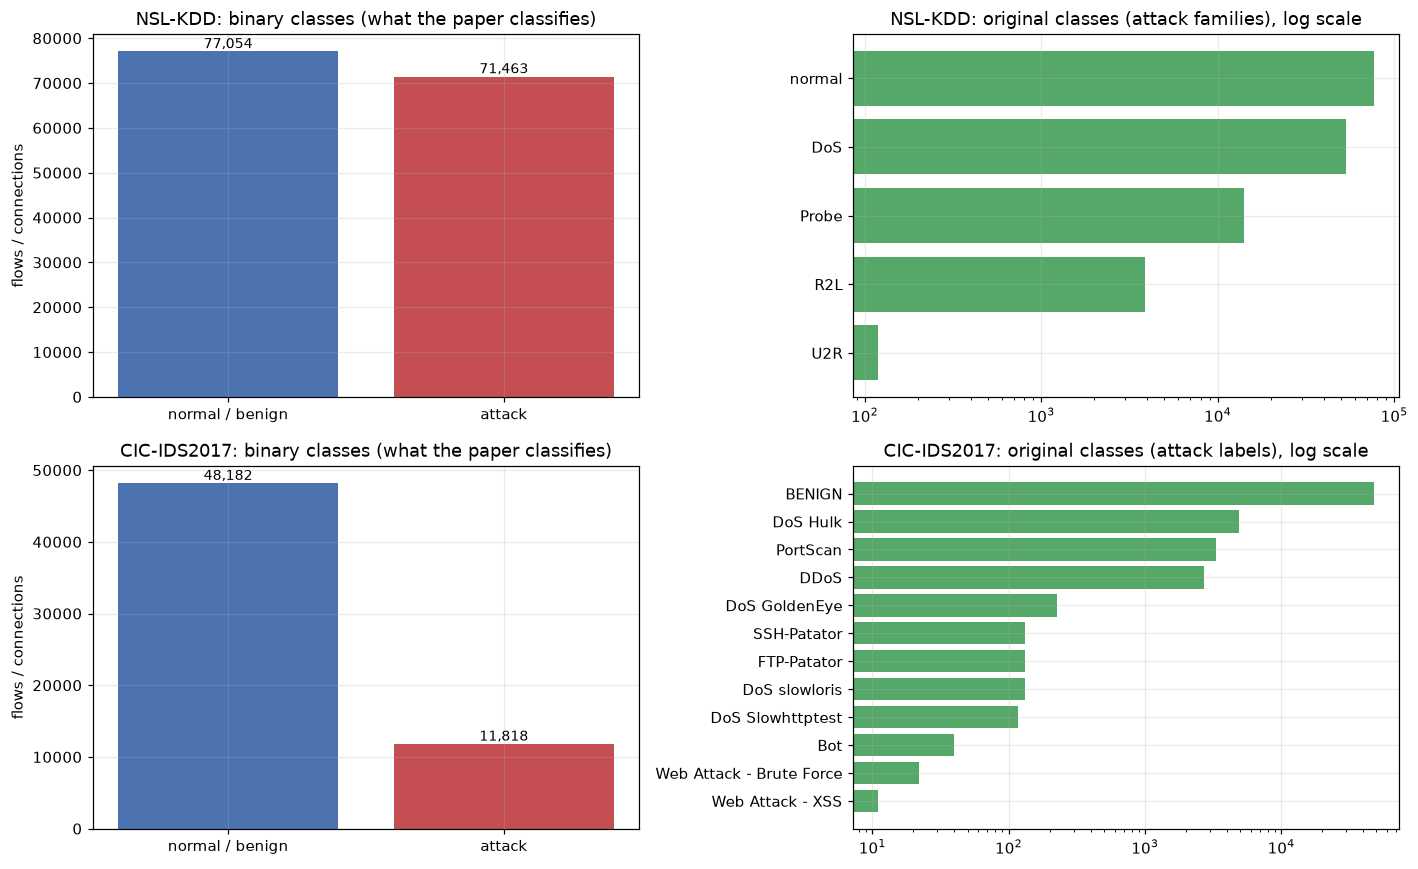

In [7]:
import textwrap
for name, d in DATA.items():
    raw = d["raw"]
    print("=" * 110)
    print(f"{d['title']}: table shape {raw.shape} | numeric feature matrix {d['X'].shape} | {len(d['names'])} features")
    print("\nOriginal label values and class counts:")
    print(raw[d["label_col"]].value_counts().to_string())
    print("\nBinary label used by the paper (0 = normal / benign, 1 = attack):", {int(k): int(v) for k, v in zip(*np.unique(d["y"], return_counts=True))})
    if name == "NSL":
        print("Attack families:", dict(pd.Series(d["fam"]).value_counts()), "| rows per official file:", dict(pd.Series(d["src"]).value_counts()))
    print("\nFeature names:")
    print(textwrap.fill(", ".join(d["names"]), 130))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for r, (name, d) in enumerate(DATA.items()):
    ser = pd.Series(d["fam"]).value_counts()
    axes[r, 0].bar(["normal / benign", "attack"], [int((d["y"] == 0).sum()), int((d["y"] == 1).sum())], color=["#4C72B0", "#C44E52"])
    axes[r, 0].set_title(f"{d['title']}: binary classes (what the paper classifies)"); axes[r, 0].set_ylabel("flows / connections")
    for i, v in enumerate([int((d["y"] == 0).sum()), int((d["y"] == 1).sum())]):
        axes[r, 0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
    axes[r, 1].barh(ser.index[::-1], ser.values[::-1], color="#55A868")
    axes[r, 1].set_xscale("log"); axes[r, 1].set_title(f"{d['title']}: original classes ({'attack families' if name == 'NSL' else 'attack labels'}), log scale")
plt.tight_layout(); plt.show()


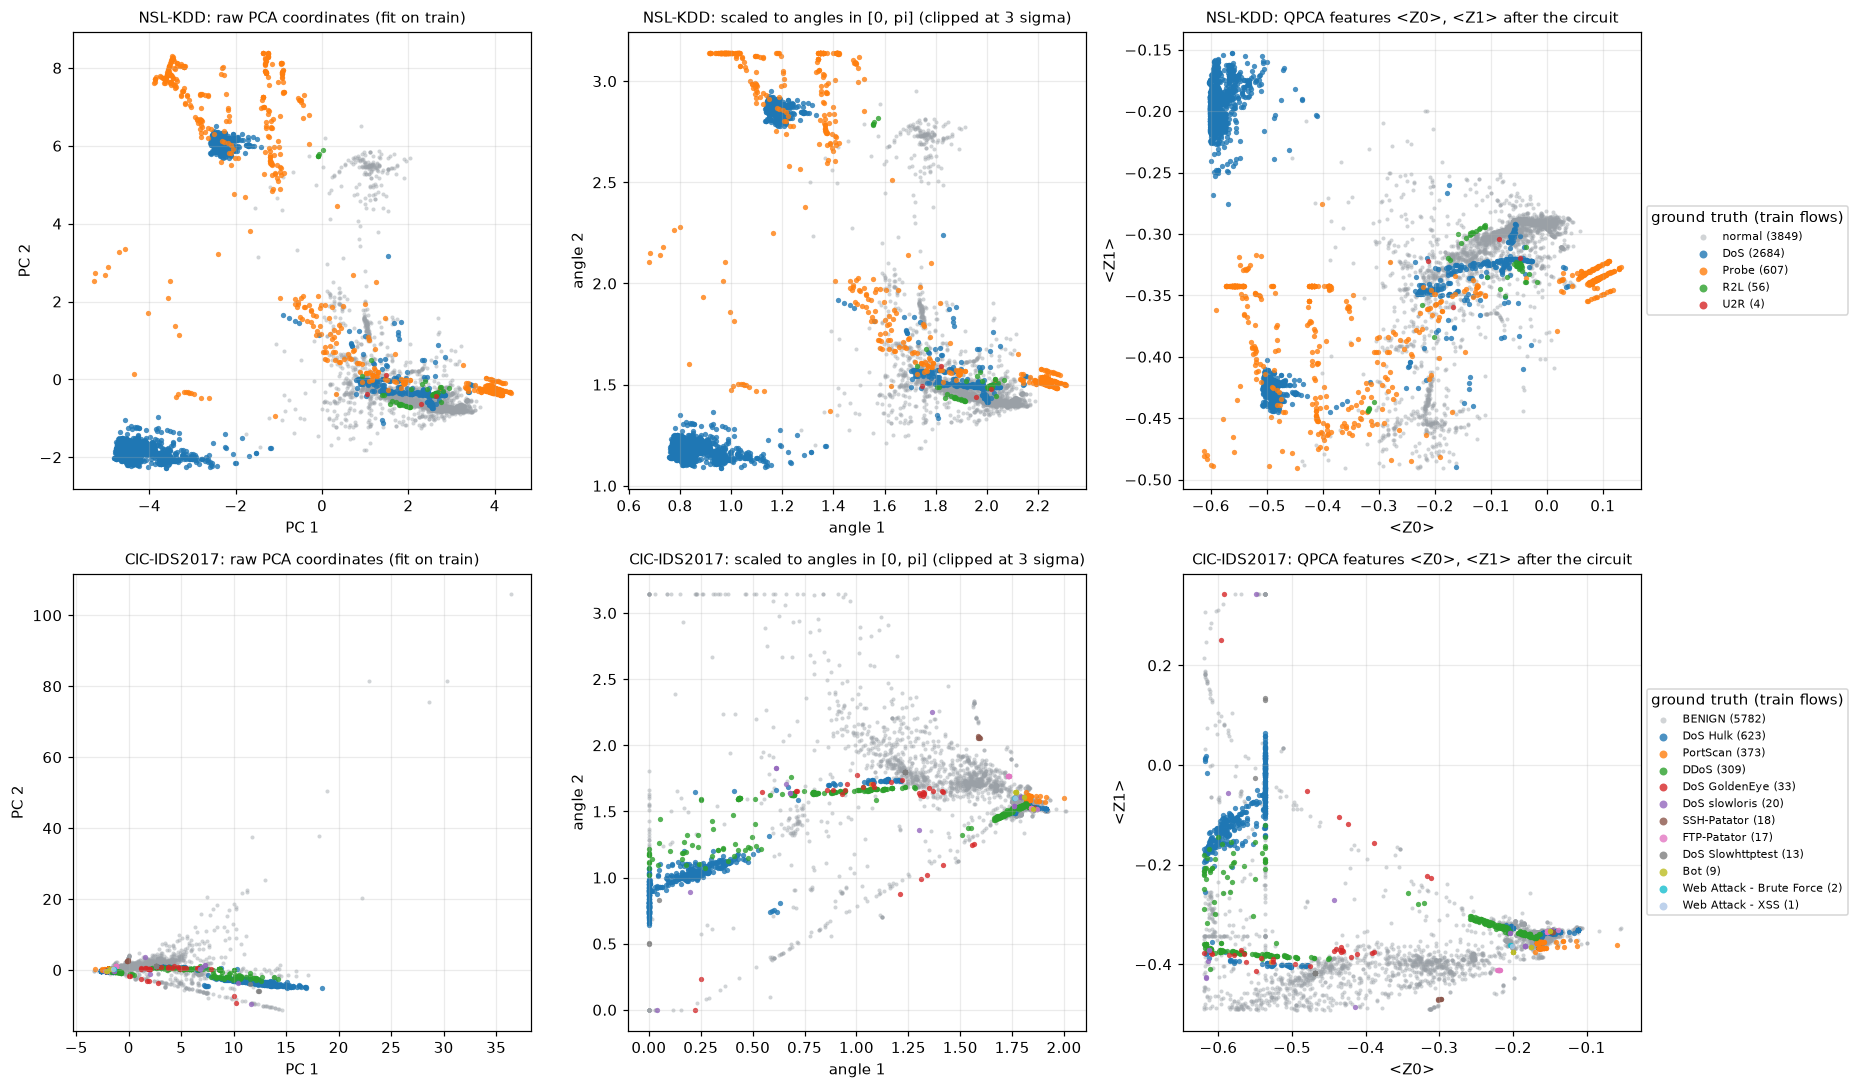

explained variance ratio of the 4 PCA components: {'NSL': array([0.087, 0.055, 0.037, 0.027]), 'CIC17': array([0.24 , 0.122, 0.088, 0.074])}


In [8]:
# Training flows of the scaled regime (seed 42): (1) raw PCA coordinates, (2) the same coordinates scaled to angles in [0, pi],
# (3) the first two QPCA features <Z_0>, <Z_1> that leave the quantum circuit. Every point is a real observation, coloured by its
# ground-truth class; multiclass attack labels are kept.
def colour_map(labels):
    uniq = [l for l in pd.Series(labels).value_counts().index]
    cols = {}
    palette = plt.cm.tab20(np.linspace(0, 1, 20))
    k = 0
    for l in uniq:
        if str(l).lower() in ("normal", "benign"):
            cols[l] = "#9aa0a6"
        else:
            cols[l] = palette[(2 * k) % 20] if k < 10 else palette[(2 * (k - 10) + 1) % 20]; k += 1
    return cols

EXPLORE = {}
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for r, name in enumerate(DATA):
    S = make_split(name, "scaled", SEED)
    R = reduce_and_encode(S, SEED, "standardised")
    Q = qpca_circuit_features(R["T"][0])
    EXPLORE[name] = (S, R, Q)
    lab = S["famtr"]; cmap = colour_map(lab)
    order = sorted(cmap, key=lambda l: (str(l).lower() not in ("normal", "benign"), -(lab == l).sum()))   # benign first, then big to small
    for c, (M, ttl, xl) in enumerate([(R["P"][0][:, :2], "raw PCA coordinates (fit on train)", "PC 1"),
                                     (R["T"][0][:, :2], "scaled to angles in [0, pi] (clipped at 3 sigma)", "angle 1"),
                                     (Q[:, :2], "QPCA features <Z0>, <Z1> after the circuit", "<Z0>")]):
        ax = axes[r, c]
        for l in order:
            m = lab == l
            ax.scatter(M[m, 0], M[m, 1], s=7 if str(l).lower() in ("normal", "benign") else 12, alpha=0.45 if str(l).lower() in ("normal", "benign") else 0.8,
                       color=cmap[l], label=f"{l} ({m.sum()})", linewidths=0)
        ax.set_title(f"{DATA[name]['title']}: {ttl}", fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(xl.replace("1", "2").replace("Z0", "Z1"))
    axes[r, 2].legend(fontsize=7, markerscale=1.5, loc="center left", bbox_to_anchor=(1.0, 0.5), title="ground truth (train flows)")
plt.tight_layout(); plt.show()
print("explained variance ratio of the 4 PCA components:",
      {n: np.round(EXPLORE[n][1]["pca"].explained_variance_ratio_, 3) for n in EXPLORE})


## Quantum Circuit Architecture

The drawings below are produced from the Qiskit circuit objects that define the two quantum models, not from illustrations. For each architecture the cell prints the number of qubits, the depth of the executed
gate list, the number of data inputs and of trainable parameters, and asserts that the fast simulation used in the experiments reproduces Qiskit's `Statevector` result on random inputs.

**Assumptions where the paper omits circuit details.**
* QPCA feature circuit: layer order (RY encoding, CZ chain, RX, CZ chain, RY), fixed constant angles from a seeded generator, ⟨Z_i⟩ read-out of all four qubits: our choice. The paper states only the qubit count (4), angle encoding, nearest-neighbour entanglement and bounded depth.
* QPCA spectral step: not a circuit here. It is the exact eigendecomposition of ρ = C / tr C (what density-matrix exponentiation plus phase estimation would return on an ideal machine); the assertion below shows its principal subspace is PCA's.
* VQC: feature map `z_feature_map(reps=1)`, ansatz `efficient_su2` with linear entanglement, `reps=2` (24 parameters, nisq) or `reps=3` (32, scaled); the paper only gives the parameter counts and "hardware-efficient". The measurement draws all four qubits, as `VQC` does, but only qubit 0 determines the class.

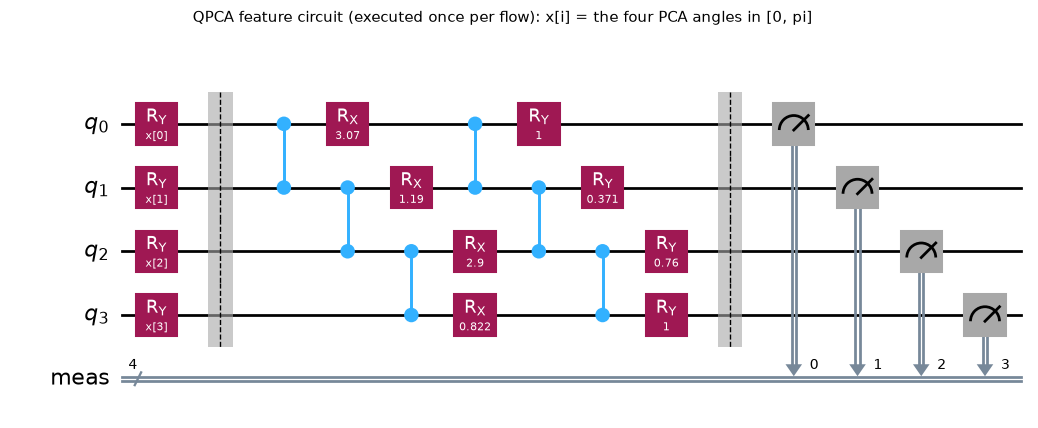

qubits = 4 | depth (before measurement) = 8 | data inputs = 4 | trainable parameters = 0 (the 8 fixed angles are constants) | gate counts: {'ry': 8, 'cz': 6, 'rx': 4, 'barrier': 1}
assertion passed: <Z_i> from Qiskit Statevector == qpca_circuit_features() on 8 random inputs (max |diff| = 4.16e-16)
cosines of the principal angles between the QPCA (eigh of rho) subspace and sklearn's PCA subspace: [1. 1. 1. 1.]


In [9]:
# (a) the QPCA feature circuit exactly as executed: angle encoding, CZ chain, fixed RX, CZ chain, fixed RY, Z-basis measurement
qc_q = build_qpca_circuit(measure=True)
fig = qc_q.draw("mpl", fold=-1, scale=0.9)
fig.suptitle("QPCA feature circuit (executed once per flow): x[i] = the four PCA angles in [0, pi]", y=1.02, fontsize=10)
display(fig); plt.close(fig)
core = build_qpca_circuit(measure=False)
print(f"qubits = {core.num_qubits} | depth (before measurement) = {core.depth()} | data inputs = {core.num_parameters} | trainable parameters = 0 "
      f"(the 8 fixed angles are constants) | gate counts: {dict(core.count_ops())}")

# equivalence of the fast simulator used in the experiments with Qiskit's own statevector simulation of this very circuit
rng_t = np.random.default_rng(SEED)
theta_t = rng_t.uniform(0, np.pi, (8, N_QUBITS))
zq = []
for th in theta_t:
    sv = Statevector(core.assign_parameters(dict(zip(core.parameters, th))))
    zq.append([sv.probabilities([q])[0] - sv.probabilities([q])[1] for q in range(N_QUBITS)])
assert np.allclose(np.array(zq), qpca_circuit_features(theta_t), atol=1e-10)
print("assertion passed: <Z_i> from Qiskit Statevector == qpca_circuit_features() on 8 random inputs (max |diff| = "
      f"{np.abs(np.array(zq) - qpca_circuit_features(theta_t)).max():.2e})")

# the spectral half of QPCA: its principal subspace is the PCA subspace (cosines of the principal angles)
S0, R0, _ = EXPLORE["NSL"]
cos = np.linalg.svd(R0["V"].T @ R0["pca"].components_.T, compute_uv=False)
print("cosines of the principal angles between the QPCA (eigh of rho) subspace and sklearn's PCA subspace:", np.round(cos, 6))
assert np.allclose(cos, 1.0, atol=1e-6)


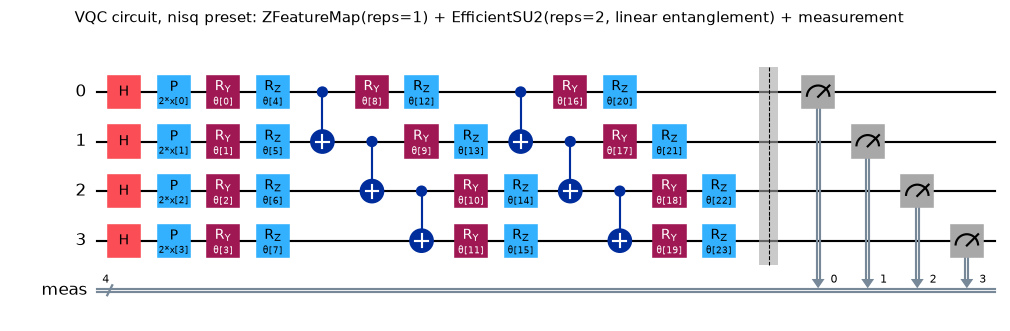

[nisq] qubits = 4 | depth of the executed gate list = 13 | data inputs = 4 | trainable parameters = 24 (paper: 24 or 32) | gates: {'ry': 12, 'rz': 12, 'cx': 6, 'h': 4, 'p': 4}
[nisq] assertion passed: P(class 1) from Qiskit Statevector == fast simulator (max |diff| = 5.55e-16)


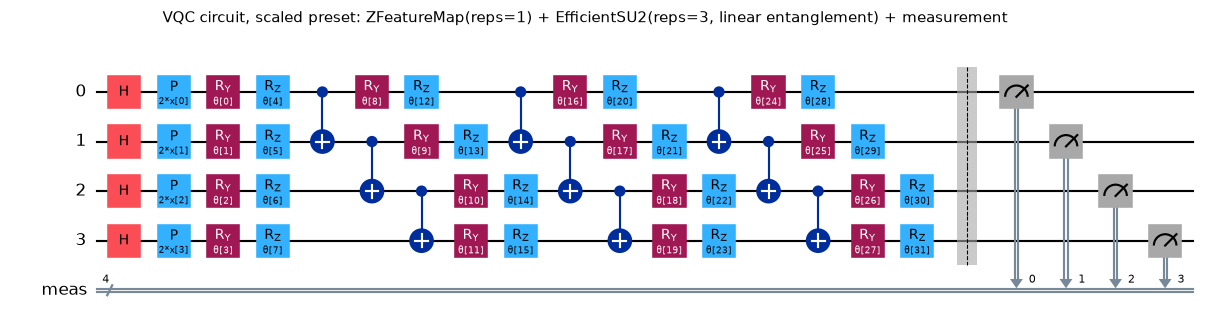

[scaled] qubits = 4 | depth of the executed gate list = 17 | data inputs = 4 | trainable parameters = 32 (paper: 24 or 32) | gates: {'ry': 16, 'rz': 16, 'cx': 9, 'h': 4, 'p': 4}
[scaled] assertion passed: P(class 1) from Qiskit Statevector == fast simulator (max |diff| = 4.44e-16)


In [10]:
# (b) the variational classifier of the QPCA -> VQC branch, one drawing per distinct architecture (nisq: reps = 2, scaled: reps = 3)
rng_t = np.random.default_rng(SEED)
for regime, reps in VQC_REPS.items():
    full = FM.compose(ANSATZ[reps])
    full_m = full.copy(); full_m.measure_all()
    fig = transpile(full_m, basis_gates=["h", "p", "ry", "rz", "cx", "measure"], optimization_level=0).draw("mpl", fold=-1, scale=0.7)   # the executed gate list, readable gate names
    fig.suptitle(f"VQC circuit, {regime} preset: ZFeatureMap(reps=1) + EfficientSU2(reps={reps}, linear entanglement) + measurement", y=1.0, fontsize=10)
    display(fig); plt.close(fig)
    flat = transpile(full, basis_gates=["h", "p", "ry", "rz", "cx"], optimization_level=0)
    print(f"[{regime}] qubits = {full.num_qubits} | depth of the executed gate list = {flat.depth()} | data inputs = {len(FM.parameters)} | "
          f"trainable parameters = {ANSATZ[reps].num_parameters} (paper: 24 or 32) | gates: {dict(flat.count_ops())}")
    # equivalence: statevector of the Qiskit circuit -> probability of reading qubit 0 as 1  ==  the fast simulator used for training
    F = rng_t.uniform(-1, 1, (6, N_QUBITS)); w = rng_t.uniform(-np.pi, np.pi, ANSATZ[reps].num_parameters)
    p1_q = []
    for f in F:
        bind = dict(zip(FM.parameters, (f + 1) * np.pi / 2)); bind.update(dict(zip(ANSATZ[reps].parameters, w)))
        probs = Statevector(full.assign_parameters(bind)).probabilities()
        p1_q.append(probs[PARITY == 1].sum())
    p1_f = vqc_p1(fm_states(F), vqc_unitary(reps, w))
    assert np.allclose(p1_q, p1_f, atol=1e-10)
    print(f"[{regime}] assertion passed: P(class 1) from Qiskit Statevector == fast simulator (max |diff| = {np.abs(np.array(p1_q) - p1_f).max():.2e})")


## 4. The seven pipelines on one split

A single run (seed 42, nisq preset, `standardised` variant) trains PCA→LR / SVM / RF, QPCA→LR / SVM / RF and QPCA→VQC on exactly the same flows and shows all of the paper's metrics, the F1 at a
validation-tuned threshold, wall-clock times, the confusion matrices (attack = positive class) and the VQC training curve. All transforms and models are fitted on the training split; the validation
split is used only to pick the alternative threshold; the test split is touched once for the numbers.


NSL-KDD | nisq preset | seed 42 | 720 train / 240 val / 240 test flows


,accuracy,precision,recall,f1,roc_auc,pr_auc,balanced_acc,f1_valthr,t_train,t_infer
pipeline,,,,,,,,,,
PCA->LR,0.7167,0.9259,0.5474,0.6881,0.8541,0.8919,0.7446,0.6884,0.0502,0.0052
PCA->SVM,0.7333,0.9740,0.5474,0.7009,0.7379,0.8614,0.7640,0.7215,0.0412,0.0176
PCA->RF,0.7500,0.9529,0.5912,0.7297,0.9373,0.9494,0.7762,0.7240,1.0637,0.3196
QPCA->LR,0.7208,0.9375,0.5474,0.6912,0.8693,0.8935,0.7495,0.6912,0.0474,0.0026
QPCA->SVM,0.7250,0.9733,0.5328,0.6887,0.9029,0.9268,0.7567,0.7182,0.0485,0.0243
QPCA->RF,0.7792,0.9468,0.6496,0.7706,0.9257,0.9433,0.8005,0.8130,1.0706,0.3144
QPCA->VQC,0.7125,0.9722,0.5109,0.6699,0.8807,0.9032,0.7458,0.6699,3.2323,0.0123



CIC-IDS2017 | nisq preset | seed 42 | 720 train / 240 val / 240 test flows


,accuracy,precision,recall,f1,roc_auc,pr_auc,balanced_acc,f1_valthr,t_train,t_infer
pipeline,,,,,,,,,,
PCA->LR,0.8750,0.9048,0.4043,0.5588,0.7186,0.6087,0.6969,0.5169,0.0549,0.0091
PCA->SVM,0.8833,1.0000,0.4043,0.5758,0.8530,0.7174,0.7021,0.7000,0.0471,0.0293
PCA->RF,0.9583,0.8936,0.8936,0.8936,0.9746,0.9531,0.9339,0.8842,1.1285,0.3325
QPCA->LR,0.8542,0.9286,0.2766,0.4262,0.6855,0.5452,0.6357,0.5205,0.0594,0.0030
QPCA->SVM,0.8667,0.9412,0.3404,0.5000,0.6502,0.5526,0.6676,0.4878,0.0630,0.0253
QPCA->RF,0.9625,0.9318,0.8723,0.9011,0.9684,0.9398,0.9284,0.8966,1.0775,0.3065
QPCA->VQC,0.8458,0.8125,0.2766,0.4127,0.5822,0.4567,0.6305,0.4242,2.7572,0.0146


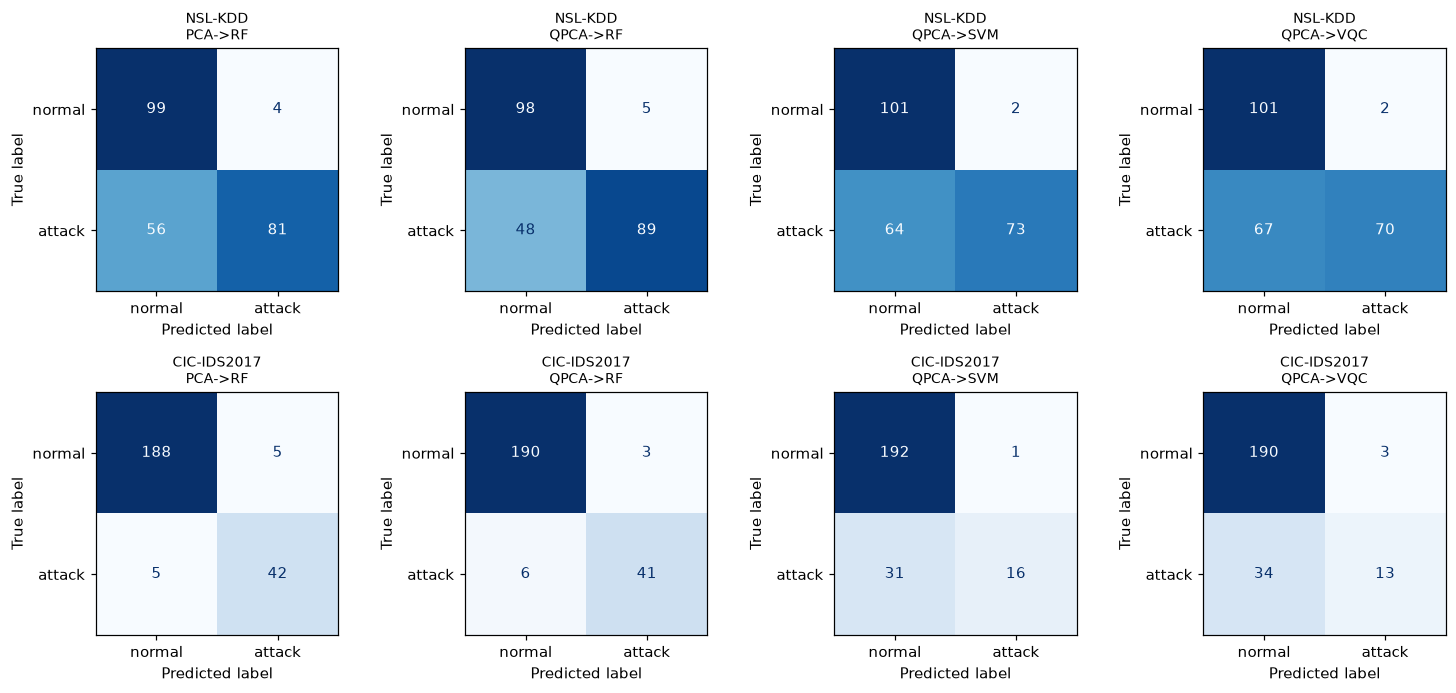

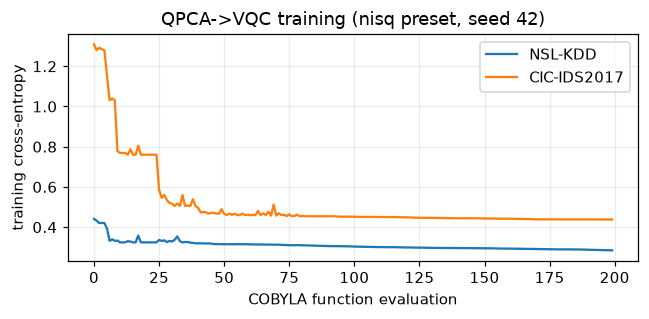

In [11]:
HEADS = ["LR", "SVM", "RF"]

def make_head(h, seed):
    if h == "LR":  return LogisticRegression(max_iter=2000)                       # CHOICE: scikit-learn defaults (C = 1)
    if h == "SVM": return SVC(kernel="rbf", C=1.0, gamma="scale")                 # CHOICE: RBF kernel, C = 1
    return RandomForestClassifier(n_estimators=N_TREES, random_state=seed, n_jobs=2)

def head_score(m, F):
    return m.decision_function(F) if hasattr(m, "decision_function") else m.predict_proba(F)[:, 1]

def best_threshold(s, y):
    """Operating point picked on the validation split (the paper: 'validation supports model and threshold selection')."""
    cand = np.unique(np.quantile(s, np.linspace(0.02, 0.98, 49)))
    f = [f1_score(y, (s >= t).astype(int), zero_division=0) for t in cand]
    return cand[int(np.argmax(f))]

def all_metrics(y, pred, s):
    return dict(accuracy=accuracy_score(y, pred), precision=precision_score(y, pred, zero_division=0), recall=recall_score(y, pred, zero_division=0),
                f1=f1_score(y, pred, zero_division=0), roc_auc=roc_auc_score(y, s), pr_auc=average_precision_score(y, s),
                balanced_acc=balanced_accuracy_score(y, pred))

def fit_eval(head, F, y, seed):
    """F = [train, validation, test] feature blocks, y = [ytr, yva, yte]. Returns metrics (default threshold + validation-tuned F1), times, predictions."""
    t0 = time.perf_counter(); m = make_head(head, seed).fit(F[0], y[0]); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); s_te = head_score(m, F[2]); pred = m.predict(F[2]); t_pred = time.perf_counter() - t0
    thr = best_threshold(head_score(m, F[1]), y[1])
    out = all_metrics(y[2], pred, s_te)
    out["f1_valthr"] = f1_score(y[2], (s_te >= thr).astype(int), zero_division=0)
    out.update(t_fit=t_fit, t_pred=t_pred)
    return out, pred, s_te, m

def run_one(name, regime, seed, variant, keep=False):
    """One dataset x regime x seed x preprocessing variant: PCA->{LR,SVM,RF}, QPCA->{LR,SVM,RF}, QPCA->VQC."""
    S = make_split(name, regime, seed)
    R = reduce_and_encode(S, seed, variant)
    t0 = time.perf_counter(); Qtr, Qva = qpca_circuit_features(R["T"][0]), qpca_circuit_features(R["T"][1]); t_c_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); Qte = qpca_circuit_features(R["T"][2]); t_c_te = time.perf_counter() - t0
    FQ = [Qtr, Qva, Qte]
    y = [S["ytr"], S["yva"], S["yte"]]
    recs, kept = [], {}
    base = dict(variant=variant, dataset=name, regime=regime, seed=seed)
    for feat, F, tf, tt in (("PCA", R["P"], R["t_pca_fit"], R["t_pca_test"]), ("QPCA", FQ, R["t_q_fit"] + t_c_fit, R["t_q_test"] + t_c_te)):
        for h in HEADS:
            m, pred, s, model = fit_eval(h, F, y, seed)
            recs.append(dict(**base, pipeline=f"{feat}->{h}", feat=feat, head=h, **m, t_train=tf + m["t_fit"], t_infer=tt + m["t_pred"]))
            kept[f"{feat}->{h}"] = (pred, s)
    reps = VQC_REPS[regime]
    t0 = time.perf_counter(); w, hist = train_vqc(FQ[0], y[0], reps, seed, VQC_MAXITER); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); s = vqc_scores(FQ[2], reps, w); t_pred = time.perf_counter() - t0
    thr = best_threshold(vqc_scores(FQ[1], reps, w), y[1])
    pred = (s >= 0.5).astype(int)
    m = all_metrics(y[2], pred, s); m["f1_valthr"] = f1_score(y[2], (s >= thr).astype(int), zero_division=0); m.update(t_fit=t_fit, t_pred=t_pred)
    recs.append(dict(**base, pipeline="QPCA->VQC", feat="QPCA", head="VQC", **m, t_train=R["t_q_fit"] + t_c_fit + t_fit, t_infer=R["t_q_test"] + t_c_te + t_pred))
    kept["QPCA->VQC"] = (pred, s)
    if keep:
        return recs, dict(preds=kept, S=S, R=R, FQ=FQ, vqc_w=w, vqc_hist=hist)
    return recs

# ---- demo: one run, seed 42, nisq preset, standardised variant -> table + confusion matrices (attack = positive class) ----
demo = {}
for name in DATA:
    recs, extra = run_one(name, "nisq", SEED, "standardised", keep=True)
    demo[name] = (pd.DataFrame(recs), extra)
    print(f"\n{DATA[name]['title']} | nisq preset | seed {SEED} | {len(extra['S']['ytr'])} train / {len(extra['S']['yva'])} val / {len(extra['S']['yte'])} test flows")
    display(demo[name][0][["pipeline", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "balanced_acc", "f1_valthr", "t_train", "t_infer"]]
            .round(4).set_index("pipeline"))

show = ["PCA->RF", "QPCA->RF", "QPCA->SVM", "QPCA->VQC"]
fig, axes = plt.subplots(2, len(show), figsize=(3.4 * len(show), 6.4))
for r, name in enumerate(DATA):
    yte = demo[name][1]["S"]["yte"]
    for c, p in enumerate(show):
        cm = confusion_matrix(yte, demo[name][1]["preds"][p][0], labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(ax=axes[r, c], colorbar=False, cmap="Blues")
        axes[r, c].set_title(f"{DATA[name]['title']}\n{p}", fontsize=9); axes[r, c].grid(False)
plt.tight_layout(); plt.show()

# training curve of the VQC (cross-entropy of the parity read-out against COBYLA function evaluations)
fig, ax = plt.subplots(figsize=(6, 3))
for name in DATA: ax.plot(demo[name][1]["vqc_hist"], label=DATA[name]["title"])
ax.set_xlabel("COBYLA function evaluation"); ax.set_ylabel("training cross-entropy"); ax.set_title("QPCA->VQC training (nisq preset, seed 42)"); ax.legend()
plt.tight_layout(); plt.show()


## 5. The multi-seed benchmark: Table 3 re-drawn

The same procedure is repeated for every dataset, regime, seed and for both preprocessing variants (`standardised` and `raw`), and the per-seed results are saved to `DATA_DIR`. The tables
re-draw the paper's Table 3 (mean ± std over the base seeds). The paper's own numbers are listed in section 9.

In [12]:
t_all = time.perf_counter()
all_recs = []
for variant in VARIANTS:
    for name in DATA:
        for regime in N_TOTAL:
            t0 = time.perf_counter()
            for seed in SEEDS:
                all_recs += run_one(name, regime, seed, variant)
            print(f"{variant:12s} {DATA[name]['title']:12s} {regime:7s} {len(SEEDS)} seeds done in {time.perf_counter() - t0:6.1f} s", flush=True)
RES = pd.DataFrame(all_recs)
RES.to_csv(os.path.join(DATA_DIR, "qc080_results_per_seed.csv"), index=False)
print(f"\n{len(RES)} model fits recorded in {(time.perf_counter() - t_all) / 60:.1f} min (saved to {DATA_DIR}/qc080_results_per_seed.csv)")

PIPES = ["PCA->LR", "PCA->SVM", "PCA->RF", "QPCA->LR", "QPCA->SVM", "QPCA->RF", "QPCA->VQC"]
def table3(df, variant, metric, seeds=None):
    """Re-draw of the paper's Table 3: mean +- std over seeds for one metric."""
    d = df[df.variant == variant]
    if seeds is not None: d = d[d.seed.isin(seeds)]
    g = d.groupby(["dataset", "regime", "pipeline"])[metric].agg(["mean", "std"]).reset_index()
    g["txt"] = g.apply(lambda r: f"{r['mean']:.3f}±{0 if np.isnan(r['std']) else r['std']:.3f}", axis=1)
    t = g.pivot(index=["dataset", "regime"], columns="pipeline", values="txt")[PIPES]
    return t.reindex([(n, r) for n in DATA for r in N_TOTAL])

N_T3 = [s for s in SEEDS if s in BASE_SEEDS]
for variant in VARIANTS:
    for metric in ("f1", "roc_auc"):
        print(f"\n===== Table 3 re-drawn: {metric.upper()} | preprocessing variant '{variant}' | seeds {N_T3} (the paper's base protocol) =====")
        display(table3(RES, variant, metric, N_T3))


standardised NSL-KDD      nisq    10 seeds done in   83.3 s


standardised NSL-KDD      scaled  10 seeds done in  161.6 s


standardised CIC-IDS2017  nisq    10 seeds done in   82.1 s


standardised CIC-IDS2017  scaled  10 seeds done in  245.4 s


raw          NSL-KDD      nisq    10 seeds done in   86.1 s


...

pipeline            PCA->LR     PCA->SVM      PCA->RF     QPCA->LR  \
dataset regime                                                       
NSL     nisq    0.900±0.034  0.770±0.054  0.914±0.021  0.893±0.032   
        scaled  0.904±0.011  0.713±0.014  0.914±0.027  0.890±0.010   
CIC17   nisq    0.752±0.083  0.864±0.017  0.978±0.010  0.728±0.099   
        scaled  0.796±0.071  0.878±0.037  0.995±0.002  0.756±0.017   

pipeline          QPCA->SVM     QPCA->RF    QPCA->VQC  
dataset regime                                         
NSL     nisq    0.898±0.050  0.915±0.017  0.898±0.028  
        scaled  0.797±0.083  0.909±0.022  0.902±0.017  
CIC17   nisq    0.706±0.087  0.978±0.012  0.654±0.089  
        scaled  0.772±0.084  0.996±0.001  0.694±0.060


===== Table 3 re-drawn: F1 | preprocessing variant 'raw' | seeds [7, 21, 42, 84, 168] (the paper's base protocol) =====


pipeline            PCA->LR     PCA->SVM      PCA->RF     QPCA->LR  \
dataset regime                                                       
NSL     nisq    0.683±0.029  0.041±0.065  0.764±0.029  0.638±0.068   
        scaled  0.676±0.022  0.332±0.455  0.779±0.014  0.642±0.060   
CIC17   nisq    0.460±0.049  0.463±0.076  0.776±0.050  0.448±0.073   
        scaled  0.468±0.024  0.461±0.021  0.897±0.013  0.411±0.028   

pipeline          QPCA->SVM     QPCA->RF    QPCA->VQC  
dataset regime                                         
NSL     nisq    0.623±0.052  0.797±0.028  0.197±0.257  
        scaled  0.644±0.057  0.798±0.014  0.653±0.076  
CIC17   nisq    0.434±0.033  0.792±0.065  0.443±0.054  
        scaled  0.456±0.019  0.877±0.012  0.379±0.055


===== Table 3 re-drawn: ROC_AUC | preprocessing variant 'raw' | seeds [7, 21, 42, 84, 168] (the paper's base protocol) =====


pipeline            PCA->LR     PCA->SVM      PCA->RF     QPCA->LR  \
dataset regime                                                       
NSL     nisq    0.847±0.019  0.850±0.014  0.935±0.020  0.766±0.055   
        scaled  0.836±0.011  0.861±0.031  0.936±0.008  0.777±0.033   
CIC17   nisq    0.642±0.033  0.714±0.056  0.934±0.016  0.678±0.072   
        scaled  0.661±0.012  0.758±0.026  0.976±0.006  0.689±0.018   

pipeline          QPCA->SVM     QPCA->RF    QPCA->VQC  
dataset regime                                         
NSL     nisq    0.761±0.063  0.922±0.034  0.740±0.170  
        scaled  0.760±0.042  0.922±0.008  0.783±0.041  
CIC17   nisq    0.710±0.058  0.939±0.020  0.644±0.024  
        scaled  0.716±0.040  0.975±0.003  0.638±0.030

## 6. Does QPCA improve the representation? Paired statistics (Section 5.2, Figure 1)

The paper's central contrasts replace PCA by QPCA while keeping classifier, data and seed fixed: CIC-IDS2017 / scaled / LR, NSL-KDD / scaled / SVM (the two primary contrasts) and NSL-KDD / nisq / SVM and
CIC-IDS2017 / nisq / LR (supportive). For each, the per-seed paired difference of ROC-AUC and of F1 gets a two-sided Wilcoxon signed-rank test (exact when possible), a Holm correction over the eight tests of the
preprocessing variant and a 95 % bootstrap interval of the mean difference (10,000 resamples over seeds). Note the arithmetic limit of the test: with n paired seeds the smallest two-sided p-value is 2 / 2ⁿ, which is
why the paper needed the extra five seeds.

,variant,contrast,metric,n,PCA,QPCA,diff,ci_lo,ci_hi,p_raw,p_holm,sig_holm_0.05
0,standardised,CIC17/scaled/LR,roc_auc,10,0.8005,0.7454,-0.0551,-0.0903,-0.0227,0.0137,0.0820,False
1,standardised,CIC17/scaled/LR,f1,10,0.6019,0.5546,-0.0473,-0.0751,-0.0217,0.0039,0.0273,True
2,standardised,NSL/scaled/SVM,roc_auc,10,0.7085,0.7777,0.0692,0.0214,0.1186,0.0840,0.2520,False
3,standardised,NSL/scaled/SVM,f1,10,0.7276,0.7211,-0.0065,-0.0161,0.0042,0.2754,0.2754,False
4,standardised,NSL/nisq/SVM,roc_auc,10,0.7629,0.8731,0.1103,0.0708,0.1485,0.0020,0.0156,True
5,standardised,NSL/nisq/SVM,f1,10,0.7416,0.7248,-0.0168,-0.0326,-0.0019,0.0840,0.2520,False
6,standardised,CIC17/nisq/LR,roc_auc,10,0.7518,0.7260,-0.0258,-0.0441,-0.0092,0.0195,0.0977,False
7,standardised,CIC17/nisq/LR,f1,10,0.5708,0.5119,-0.0589,-0.1000,-0.0210,0.0195,0.0977,False
8,raw,CIC17/scaled/LR,roc_auc,10,0.6508,0.6700,0.0192,0.0110,0.0276,0.0098,0.0391,True
9,raw,CIC17/scaled/LR,f1,10,0.4568,0.4180,-0.0387,-0.0570,-0.0219,0.0020,0.0156,True


smallest p the exact Wilcoxon test can give with n = 10 seeds: 0.00195 (two-sided) -> with Holm over 8 tests the best possible p_Holm is 0.0156


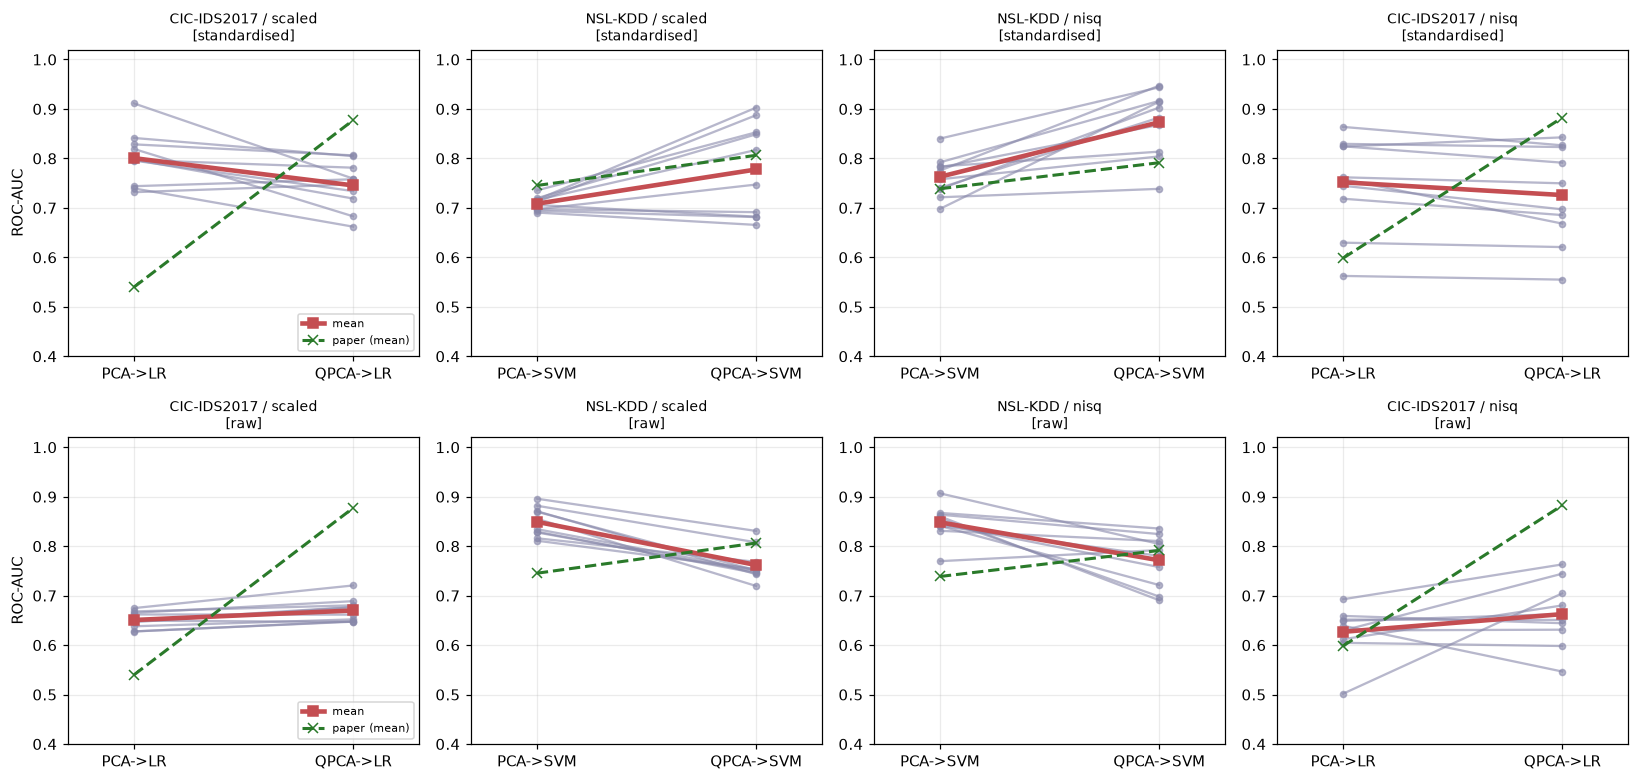

In [13]:
# The four "central" PCA -> QPCA contrasts of the paper (same classifier head, same seeds, same splits) and the paper's numbers (Section 5.2, Figure 1)
CENTRAL = [("CIC17", "scaled", "LR"), ("NSL", "scaled", "SVM"), ("NSL", "nisq", "SVM"), ("CIC17", "nisq", "LR")]
PAPER_CENTRAL = {   # (PCA ROC-AUC, QPCA ROC-AUC, Holm p or None, paired mean diff, bootstrap CI)
    ("CIC17", "scaled", "LR"):  dict(pca=0.5397, qpca=0.8772, p_holm=0.0156, diff=0.3375, ci=(0.3146, 0.3601), f1=(0.3261, 0.3927)),
    ("NSL", "scaled", "SVM"):   dict(pca=0.7453, qpca=0.8063, p_holm=0.0273, diff=0.0610, ci=(0.0376, 0.0822), f1=(0.6849, 0.6958)),
    ("NSL", "nisq", "SVM"):     dict(pca=0.7387, qpca=0.7913, p_holm=0.0586, diff=0.0526, ci=None, f1=None),
    ("CIC17", "nisq", "LR"):    dict(pca=0.5982, qpca=0.8824, p_holm=None, diff=0.2842, ci=None, f1=None),
}

def paired_arrays(df, variant, dataset, regime, head, metric):
    d = df[(df.variant == variant) & (df.dataset == dataset) & (df.regime == regime)]
    a = d[d.pipeline == f"PCA->{head}"].sort_values("seed")[metric].values
    b = d[d.pipeline == f"QPCA->{head}"].sort_values("seed")[metric].values
    return a, b

def bootstrap_ci(d, B=10000, seed=SEED):
    r = np.random.default_rng(seed)
    means = r.choice(d, size=(B, len(d)), replace=True).mean(1)
    return np.percentile(means, [2.5, 97.5])

def holm_adjust(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

rows = []
for variant in VARIANTS:
    block = []
    for (ds, rg, h) in CENTRAL:
        for metric in ("roc_auc", "f1"):
            a, b = paired_arrays(RES, variant, ds, rg, h, metric)
            d = b - a
            try:    p = wilcoxon(d, zero_method="wilcox", method="auto").pvalue if np.any(d != 0) else 1.0
            except Exception: p = np.nan
            lo, hi = bootstrap_ci(d)
            block.append(dict(variant=variant, contrast=f"{ds}/{rg}/{h}", metric=metric, n=len(d), PCA=a.mean(), QPCA=b.mean(), diff=d.mean(),
                              ci_lo=lo, ci_hi=hi, p_raw=p))
    adj = holm_adjust([r["p_raw"] for r in block])          # Holm over the 8 priority tests of this preprocessing variant
    for r, pa in zip(block, adj): r["p_holm"] = pa
    rows += block
STATS = pd.DataFrame(rows)
STATS["sig_holm_0.05"] = STATS["p_holm"] < 0.05
pd.set_option("display.width", 200)
display(STATS.round(4))
print(f"smallest p the exact Wilcoxon test can give with n = {len(SEEDS)} seeds: {2 / 2 ** len(SEEDS):.5f} (two-sided) -> with Holm over 8 tests the best possible p_Holm is {min(1.0, 8 * 2 / 2 ** len(SEEDS)):.4f}")

# Figure 1 re-drawn: ROC-AUC, PCA versus QPCA, one line per seed, for the four central contrasts
fig, axes = plt.subplots(len(VARIANTS), 4, figsize=(15, 3.6 * len(VARIANTS)), squeeze=False)
for r, variant in enumerate(VARIANTS):
    for c, (ds, rg, h) in enumerate(CENTRAL):
        a, b = paired_arrays(RES, variant, ds, rg, h, "roc_auc")
        ax = axes[r, c]
        for ai, bi in zip(a, b): ax.plot([0, 1], [ai, bi], color="#8888aa", alpha=0.6, marker="o", ms=4)
        ax.plot([0, 1], [a.mean(), b.mean()], color="#C44E52", lw=3, marker="s", label="mean")
        pc = PAPER_CENTRAL[(ds, rg, h)]
        ax.plot([0, 1], [pc["pca"], pc["qpca"]], color="#2a7a2a", lw=2, ls="--", marker="x", label="paper (mean)")
        ax.set_xticks([0, 1]); ax.set_xticklabels([f"PCA->{h}", f"QPCA->{h}"]); ax.set_xlim(-0.3, 1.3); ax.set_ylim(0.4, 1.02)
        ax.set_title(f"{DATA[ds]['title']} / {rg}\n[{variant}]", fontsize=9)
        if c == 0: ax.set_ylabel("ROC-AUC"); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()


## 7. Cost-performance trade-off (Section 5.4, Figure 2)

Wall-clock training and inference times of every pipeline (the QPCA times include the simulation of the feature circuit) and the cost-performance picture of the paper's Figure 2. **Caution:** our VQC is trained on an
exact 16-dimensional statevector with a hand-made unitary, which is far faster than the circuit-by-circuit primitives route that `qiskit-machine-learning` uses and that the paper's 128 to 270 s most likely reflect. To
make the paper's cost claim checkable the cell therefore also times the real `VQC` class (`StatevectorSampler`, shots) for a few COBYLA iterations on 100 flows, checks that its outputs agree with the fast simulator,
and extrapolates to this notebook's training budget.

Mean training time (s) and inference time (s) per pipeline, 'standardised' variant, exact-statevector simulation of the circuits


pipeline        PCA->LR  PCA->SVM  PCA->RF  QPCA->LR  QPCA->SVM  QPCA->RF  QPCA->VQC
dataset regime                                                                      
CIC17   nisq     0.0296    0.0323   0.9381    0.0404     0.0430    0.9105     3.3017
        scaled   0.2129    2.0949   2.8879    0.2554     2.1503    3.0814     5.2489
NSL     nisq     0.0334    0.0321   1.1008    0.0473     0.0463    1.0035     2.8694
        scaled   0.2865    0.8367   2.4838    0.2503     0.9831    2.3743     4.4938

pipeline        PCA->LR  PCA->SVM  PCA->RF  QPCA->LR  QPCA->SVM  QPCA->RF  QPCA->VQC
dataset regime                                                                      
CIC17   nisq     0.0027    0.0211   0.2750    0.0024     0.0250    0.2459     0.0132
        scaled   0.0070    1.8535   0.3715    0.0107     2.0382    0.3609     0.0254
NSL     nisq     0.0028    0.0167   0.3287    0.0030     0.0188    0.3078     0.0096
        scaled   0.0098    0.7520   0.3277    0.0102     1.0247    0.3167     0.0228

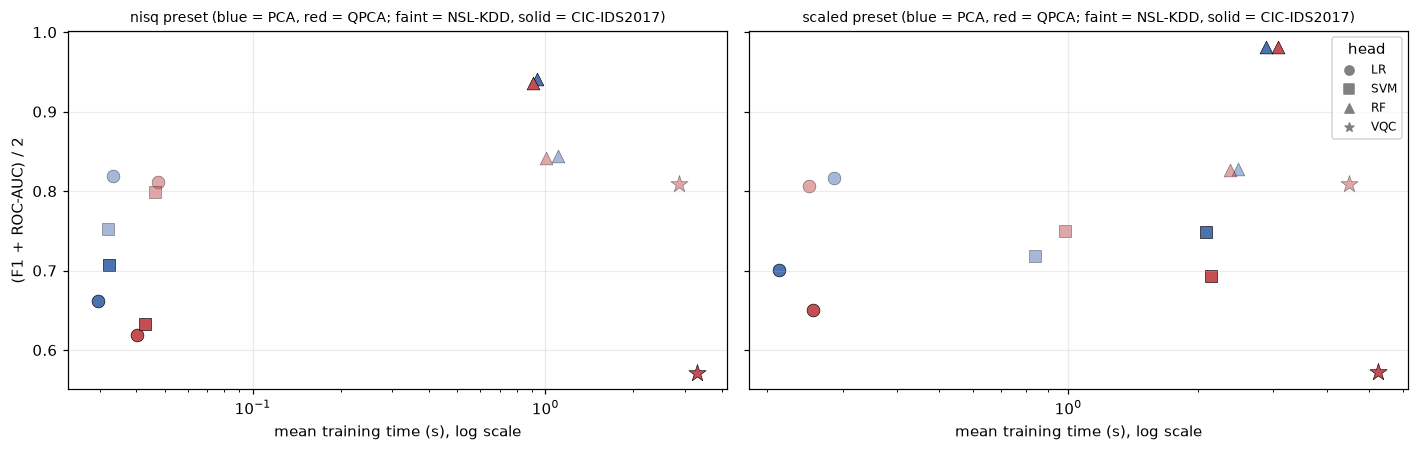

Qiskit VQC (StatevectorSampler, 2048 shots): 26 loss evaluations on 100 samples took 74.8 s -> 28.76 ms per sample per evaluation


real VQC vs fast simulator, P(class 1) on 20 samples: max |diff| = 0.025 (shot noise of 2048 shots is about 0.01-0.02)
Extrapolated training time of the Qiskit-primitives route with this notebook's budget (N_train x VQC_MAXITER evaluations): {'nisq': '69.0 min', 'scaled': '690.1 min'} | paper reports 128.7 s (CIC17 nisq), 257.0 s (CIC17 scaled), 269.5 s (NSL scaled)


In [14]:
from matplotlib.ticker import NullFormatter
cost = (RES[RES.variant == "standardised"].groupby(["dataset", "regime", "pipeline"])[["t_train", "t_infer"]].mean()
        .unstack("pipeline")[["t_train", "t_infer"]])
print("Mean training time (s) and inference time (s) per pipeline, 'standardised' variant, exact-statevector simulation of the circuits")
display(cost["t_train"][PIPES].round(4)); display(cost["t_infer"][PIPES].round(4))

# Figure 2 re-drawn: cost (mean training time) against aggregate predictive performance = mean of (F1, ROC-AUC) over seeds
agg = (RES[RES.variant == "standardised"].assign(perf=lambda d: (d.f1 + d.roc_auc) / 2)
       .groupby(["dataset", "regime", "pipeline"]).agg(perf=("perf", "mean"), t=("t_train", "mean")).reset_index())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
mk = {"LR": "o", "SVM": "s", "RF": "^", "VQC": "*"}
for ax, rg in zip(axes, N_TOTAL):
    for _, r in agg[agg.regime == rg].iterrows():
        feat, head = r.pipeline.split("->")
        ax.scatter(r.t, r.perf, marker=mk[head], s=140 if head == "VQC" else 70, color="#C44E52" if feat == "QPCA" else "#4C72B0",
                   edgecolor="k", linewidths=0.4, alpha=0.5 if r.dataset == "NSL" else 1.0)
    ax.set_xscale("log"); ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xlabel("mean training time (s), log scale"); ax.set_title(f"{rg} preset (blue = PCA, red = QPCA; faint = NSL-KDD, solid = CIC-IDS2017)", fontsize=9)
axes[0].set_ylabel("(F1 + ROC-AUC) / 2")
for head, m in mk.items(): axes[1].scatter([], [], marker=m, color="grey", label=head)
axes[1].legend(title="head", fontsize=8)
plt.tight_layout(); plt.show()

# ---- reference timing of the *Qiskit primitives route* (what the paper most likely ran): real qiskit-machine-learning VQC ----
REF_N, REF_ITERS = (50, 3) if FAST_MODE else (100, 8)
ex = demo["NSL"][1]
Xref = (ex["FQ"][0][:REF_N] + 1.0) * np.pi / 2.0                    # the same angles the fast simulator feeds into the Z feature map
yref = ex["S"]["ytr"][:REF_N]
w0 = np.random.default_rng(SEED).uniform(-np.pi, np.pi, ANSATZ[2].num_parameters)
evals = []
vqc_ref = VQC(feature_map=FM, ansatz=ANSATZ[2], optimizer=COBYLA(maxiter=REF_ITERS), sampler=StatevectorSampler(default_shots=SHOTS, seed=SEED),
              initial_point=w0, callback=lambda w, l: evals.append(l))
t0 = time.perf_counter(); vqc_ref.fit(Xref, yref); t_ref = time.perf_counter() - t0
per = t_ref / max(len(evals), 1) / REF_N
print(f"Qiskit VQC (StatevectorSampler, {SHOTS} shots): {len(evals)} loss evaluations on {REF_N} samples took {t_ref:.1f} s "
      f"-> {1000 * per:.2f} ms per sample per evaluation")
# agreement of the real VQC forward pass with the fast simulator at the weights it ended with (shot noise only)
pq = vqc_ref.neural_network.forward(Xref[:20], vqc_ref.weights)[:, 1]
pf = vqc_p1(fm_states(ex["FQ"][0][:20]), vqc_unitary(2, vqc_ref.weights))
print(f"real VQC vs fast simulator, P(class 1) on 20 samples: max |diff| = {np.abs(pq - pf).max():.3f} (shot noise of {SHOTS} shots is about 0.01-0.02)")
assert np.abs(pq - pf).max() < 0.08
n_tr = {rg: int(round(N_TOTAL[rg] * (1 - TEST_FRAC - VAL_FRAC))) for rg in N_TOTAL}
REF_EST = {rg: per * n_tr[rg] * VQC_MAXITER for rg in N_TOTAL}
print("Extrapolated training time of the Qiskit-primitives route with this notebook's budget (N_train x VQC_MAXITER evaluations):",
      {rg: f"{v / 60:.1f} min" for rg, v in REF_EST.items()}, "| paper reports 128.7 s (CIC17 nisq), 257.0 s (CIC17 scaled), 269.5 s (NSL scaled)")


## 8. Extension (not in the paper): shot noise and a calibrated fake device

The paper states that no calibrated hardware noise was injected and lists fake-backend or noise simulations as future work. As a small step in that direction the QPCA circuit is run for a stratified subset of the
test flows of the single run in section 4 (nisq preset, seed 42), (i) exactly, (ii) with an ideal sampler and 2048 shots, (iii) on `AerSimulator.from_backend(FakeSherbrooke)` (transpiled to qubits 0 to 3; ECR / SX / RZ basis, relaxation, gate and
read-out errors). The classifiers stay trained on exact training features ("train in simulation, deploy on a device"), so the table measures how robust each head is to a perturbed feature stage. With only a
few dozen test flows (a few attacks for CIC-IDS2017) these are indications, not statistics.

In [15]:
# NISQ extension (NOT in the paper, which states that no calibrated noise was injected): push the QPCA circuit of a test subset through
#   (i) the exact simulator, (ii) an ideal sampler with SHOTS shots, (iii) AerSimulator.from_backend(FakeSherbrooke) = calibrated 127-qubit noise model.
# The classifier heads are trained on exact training features and applied to the noisy test features ("trained in simulation, deployed on a device").
try:
    from qiskit_aer import AerSimulator
    from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
    backend = FakeSherbrooke()
    sim_noisy = AerSimulator.from_backend(backend, seed_simulator=SEED)
    sim_ideal = AerSimulator(seed_simulator=SEED)
    qc_m = build_qpca_circuit(measure=True)
    tqc = transpile(qc_m, backend, initial_layout=list(range(N_QUBITS)), optimization_level=1, seed_transpiler=SEED)
    print(f"transpiled for {backend.name}: depth {tqc.depth()}, gates {dict(tqc.count_ops())}")

    def z_from_counts(counts):
        z = np.zeros(N_QUBITS); tot = sum(counts.values())
        for key, c in counts.items():
            bits = key.replace(" ", "")[::-1]
            z += c * np.array([1 - 2 * int(bits[q]) for q in range(N_QUBITS)])
        return z / tot

    def device_features(sim, circ, T):
        circs = [circ.assign_parameters(dict(zip(circ.parameters, th))) for th in T]
        res = sim.run(circs, shots=SHOTS).result()
        return np.array([z_from_counts(res.get_counts(i)) for i in range(len(circs))])

    noise_rows = []
    for name in DATA:
        S, R, FQ, w = demo[name][1]["S"], demo[name][1]["R"], demo[name][1]["FQ"], demo[name][1]["vqc_w"]
        sel = train_test_split(np.arange(len(S["yte"])), train_size=min(NOISE_N, len(S["yte"]) - 2), stratify=S["yte"], random_state=SEED)[0]
        T_sub, y_sub = R["T"][2][sel], S["yte"][sel]
        feats = {"exact": qpca_circuit_features(T_sub)}
        t0 = time.perf_counter(); feats[f"{SHOTS} shots, no noise"] = device_features(sim_ideal, qc_m, T_sub)
        feats["FakeSherbrooke noise model"] = device_features(sim_noisy, tqc, T_sub); t_dev = time.perf_counter() - t0
        for h in HEADS:
            model = make_head(h, SEED).fit(FQ[0], S["ytr"])
            for k, F in feats.items():
                s = head_score(model, F)
                noise_rows.append(dict(dataset=DATA[name]["title"], head=h, test_features=k, mean_abs_dZ=np.abs(F - feats["exact"]).mean(),
                                       roc_auc=roc_auc_score(y_sub, s), f1=f1_score(y_sub, model.predict(F), zero_division=0)))
        for k, F in feats.items():
            s = vqc_scores(F, VQC_REPS["nisq"], w)
            noise_rows.append(dict(dataset=DATA[name]["title"], head="VQC", test_features=k, mean_abs_dZ=np.abs(F - feats["exact"]).mean(),
                                   roc_auc=roc_auc_score(y_sub, s), f1=f1_score(y_sub, (s >= 0.5).astype(int), zero_division=0)))
        print(f"{DATA[name]['title']}: {len(sel)} test flows x 2 noisy circuits in {t_dev:.0f} s")
    NOISE = pd.DataFrame(noise_rows)
    display(NOISE.round(4).pivot_table(index=["dataset", "head"], columns="test_features", values=["roc_auc", "f1"]).round(3))
    print("mean |Delta<Z>| per feature:"); display(NOISE.groupby(["dataset", "test_features"]).mean_abs_dZ.mean().round(4).unstack())
except Exception as e:      # the extension is optional; the paper's experiments above do not depend on it
    NOISE = None
    print("Noise extension skipped:", type(e).__name__, str(e)[:200])


transpiled for fake_sherbrooke: depth 24, gates {'rz': 30, 'sx': 26, 'ecr': 6, 'measure': 4, 'barrier': 2, 'x': 2}


NSL-KDD: 150 test flows x 2 noisy circuits in 9 s


CIC-IDS2017: 150 test flows x 2 noisy circuits in 9 s


f1                                                roc_auc                                  
test_features    2048 shots, no noise FakeSherbrooke noise model  exact 2048 shots, no noise FakeSherbrooke noise model  exact
dataset     head                                                                                                              
CIC-IDS2017 LR                  0.389                      0.389  0.389                0.642                      0.661  0.634
            RF                  0.511                      0.439  0.946                0.758                      0.642  0.971
            SVM                 0.474                      0.513  0.474                0.626                      0.645  0.600
            VQC                 0.368                      0.333  0.378                0.591                      0.610  0.499
NSL-KDD     LR                  0.676                      0.667  0.667                0.855                      0.853  0.850
            RF                  0.782                      0.709  0.776                0.795                      0.726  0.924
            SVM                 0.667                      0.656  0.667                0.870                      0.883  0.891
            VQC                 0.646                      0.646  0.646                0.868                      0.865  0.865

mean |Delta<Z>| per feature:


test_features,"2048 shots, no noise",FakeSherbrooke noise model,exact
dataset,,,
CIC-IDS2017,0.0155,0.0348,0.0
NSL-KDD,0.0152,0.0349,0.0


## 9. Side by side with the paper: a verdict per claim

Three blocks: (A) the paper's 56 Table 3 numbers cell by cell (tolerance 0.02), (B) the quantitative claims of Section 5.2 (the central contrasts), (C) the qualitative claims. Verdict vocabulary: **reproduced**
(within tolerance, or the qualitative statement holds), **not reached** / **exceeded** (our number is lower / higher than the paper's by more than the tolerance), **not reproduced**. Every row is shown for both
preprocessing variants because the paper does not say whether features were standardised before PCA.

In [16]:
# ---------- the paper's Table 3 (mean, std), column order PCA: LR SVM RF | QPCA: LR SVM RF VQC ----------
PAPER_T3 = {
 ("CIC17", "nisq",   "f1"):      ([0.262, 0.568, 0.865, 0.241, 0.572, 0.809, 0.349], [0.122, 0.098, 0.097, 0.235, 0.100, 0.128, 0.110]),
 ("CIC17", "nisq",   "roc_auc"): ([0.598, 0.887, 0.952, 0.882, 0.884, 0.955, 0.879], [0.073, 0.021, 0.066, 0.029, 0.015, 0.059, 0.021]),
 ("CIC17", "scaled", "f1"):      ([0.326, 0.585, 0.898, 0.393, 0.553, 0.890, 0.307], [0.108, 0.042, 0.051, 0.075, 0.070, 0.059, 0.054]),
 ("CIC17", "scaled", "roc_auc"): ([0.540, 0.885, 0.984, 0.877, 0.872, 0.983, 0.829], [0.053, 0.012, 0.015, 0.022, 0.036, 0.014, 0.058]),
 ("NSL",   "nisq",   "f1"):      ([0.666, 0.673, 0.697, 0.662, 0.629, 0.694, 0.712], [0.018, 0.033, 0.018, 0.171, 0.165, 0.078, 0.206]),
 ("NSL",   "nisq",   "roc_auc"): ([0.850, 0.739, 0.859, 0.879, 0.791, 0.847, 0.810], [0.016, 0.025, 0.011, 0.020, 0.044, 0.027, 0.062]),
 ("NSL",   "scaled", "f1"):      ([0.666, 0.685, 0.704, 0.640, 0.696, 0.689, 0.723], [0.036, 0.023, 0.031, 0.133, 0.129, 0.053, 0.166]),
 ("NSL",   "scaled", "roc_auc"): ([0.838, 0.745, 0.849, 0.872, 0.806, 0.834, 0.854], [0.008, 0.055, 0.016, 0.015, 0.042, 0.019, 0.020]),
}
TOL = 0.02          # CLAUDE.md / brief: "reproduced" = within 0.02 (F1 or ROC-AUC); otherwise "not reached" / "exceeded" with the gap

def verdict(nb, paper, tol=TOL):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

# ---------- A. all 56 cells of Table 3 ----------
cells = []
for variant in VARIANTS:
    d = RES[(RES.variant == variant) & (RES.seed.isin(N_T3))]
    for (ds, rg, metric), (mu, sd) in PAPER_T3.items():
        for pipe, pm, ps in zip(PIPES, mu, sd):
            x = d[(d.dataset == ds) & (d.regime == rg) & (d.pipeline == pipe)][metric]
            cells.append(dict(variant=variant, dataset=ds, regime=rg, metric=metric, pipeline=pipe, paper=pm, paper_std=ps, notebook=x.mean(), nb_std=x.std(), diff=x.mean() - pm))
CELLS = pd.DataFrame(cells)
CELLS["verdict"] = [verdict(r.notebook, r.paper) for r in CELLS.itertuples()]
CELLS["within_0.05"] = CELLS["diff"].abs() <= 0.05
summ = CELLS.groupby(["variant", "metric"]).agg(cells=("diff", "size"), within_0_02=("verdict", lambda v: int((v == "reproduced").sum())), within_0_05=("within_0.05", "sum"),
                                                mean_abs_gap=("diff", lambda v: v.abs().mean()), mean_signed_gap=("diff", "mean"))
print("Table 3, cell by cell (mean over the base seeds; tolerance 0.02):"); display(summ.round(3))
print("\nBy dataset / pipeline family (share of cells within 0.05):")
CELLS["family"] = np.where(CELLS.pipeline.str.endswith("RF"), "random forest", np.where(CELLS.pipeline.str.endswith("VQC"), "VQC", "LR / SVM"))
display(CELLS.groupby(["variant", "dataset", "family"])["within_0.05"].mean().round(2).unstack("family"))

# ---------- B. the paper's headline claims ----------
claims = []
def add(claim, paper_txt, nb_by_variant, verdict_by_variant):
    claims.append(dict(claim=claim, paper=paper_txt, **{f"notebook [{v}]": nb_by_variant[v] for v in VARIANTS}, **{f"verdict [{v}]": verdict_by_variant[v] for v in VARIANTS}))

def S_(variant, key, metric): return STATS[(STATS.variant == variant) & (STATS.contrast == key) & (STATS.metric == metric)].iloc[0]
for (ds, rg, h) in CENTRAL:
    key, pc = f"{ds}/{rg}/{h}", PAPER_CENTRAL[(ds, rg, h)]
    add(f"{key}: PCA->{h} ROC-AUC", f"{pc['pca']:.4f}", {v: f"{S_(v, key, 'roc_auc').PCA:.4f}" for v in VARIANTS}, {v: verdict(S_(v, key, 'roc_auc').PCA, pc["pca"]) for v in VARIANTS})
    add(f"{key}: QPCA->{h} ROC-AUC", f"{pc['qpca']:.4f}", {v: f"{S_(v, key, 'roc_auc').QPCA:.4f}" for v in VARIANTS}, {v: verdict(S_(v, key, 'roc_auc').QPCA, pc["qpca"]) for v in VARIANTS})
    add(f"{key}: paired ROC-AUC gain QPCA - PCA", f"{pc['diff']:+.4f}", {v: f"{S_(v, key, 'roc_auc')['diff']:+.4f} [{S_(v, key, 'roc_auc').ci_lo:+.3f}, {S_(v, key, 'roc_auc').ci_hi:+.3f}]" for v in VARIANTS},
        {v: verdict(S_(v, key, 'roc_auc')["diff"], pc["diff"], 0.05) for v in VARIANTS})
    if pc["p_holm"] is not None:
        paper_sig = pc["p_holm"] < 0.05
        add(f"{key}: ROC-AUC gain significant after Holm", f"{'yes' if paper_sig else 'no'} (p_Holm = {pc['p_holm']})",
            {v: f"{'yes' if S_(v, key, 'roc_auc').p_holm < 0.05 else 'no'} (p_Holm = {S_(v, key, 'roc_auc').p_holm:.4f})" for v in VARIANTS},
            {v: "reproduced" if (S_(v, key, 'roc_auc').p_holm < 0.05) == paper_sig else "not reproduced" for v in VARIANTS})
    if pc["f1"] is not None:
        add(f"{key}: F1 PCA -> QPCA (paper: change not significant after Holm)", f"{pc['f1'][0]:.4f} -> {pc['f1'][1]:.4f}",
            {v: f"{S_(v, key, 'f1').PCA:.4f} -> {S_(v, key, 'f1').QPCA:.4f} (p_Holm = {S_(v, key, 'f1').p_holm:.3f})" for v in VARIANTS},
            {v: ("reproduced" if S_(v, key, 'f1').p_holm >= 0.05 else "not reproduced") for v in VARIANTS})

# ---------- C. qualitative claims ----------
def mean_of(variant, ds, rg, pipe, metric, col="mean"):
    x = RES[(RES.variant == variant) & (RES.dataset == ds) & (RES.regime == rg) & (RES.pipeline == pipe) & (RES.seed.isin(N_T3))][metric]
    return x.mean() if col == "mean" else x.std()

nb, vd = {}, {}
for v in VARIANTS:
    wins = [mean_of(v, ds, rg, f"QPCA->{h}", "roc_auc") > mean_of(v, ds, rg, f"PCA->{h}", "roc_auc") for ds in DATA for rg in N_TOTAL for h in HEADS]
    wins_f1 = [mean_of(v, ds, rg, f"QPCA->{h}", "f1") > mean_of(v, ds, rg, f"PCA->{h}", "f1") for ds in DATA for rg in N_TOTAL for h in HEADS]
    nb[v] = f"QPCA > PCA in ROC-AUC {sum(wins)}/12 and in F1 {sum(wins_f1)}/12 pairs"; vd[v] = "reproduced" if 0 < sum(wins) < 12 and 0 < sum(wins_f1) < 12 else "not reproduced"
add("No universal QPCA advantage (mixed wins/losses over the 12 dataset x regime x head pairs)", "mixed (Table 3)", nb, vd)

nb, vd = {}, {}
for v in VARIANTS:
    best = {rg: max(PIPES, key=lambda p: mean_of(v, "CIC17", rg, p, "f1")) for rg in N_TOTAL}
    nb[v] = str(best); vd[v] = "reproduced" if all(b.endswith("RF") for b in best.values()) else "not reproduced"
add("CIC17: a tree-based pipeline has the highest F1 (both presets)", "PCA->RF / QPCA->RF", nb, vd)

nb, vd = {}, {}
for v in VARIANTS:
    gaps = {rg: mean_of(v, "CIC17", rg, "QPCA->RF", "f1") - mean_of(v, "CIC17", rg, "QPCA->VQC", "f1") for rg in N_TOTAL}
    nb[v] = {rg: round(g, 3) for rg, g in gaps.items()}; vd[v] = "reproduced" if all(g > 0.2 for g in gaps.values()) else "not reproduced"
add("CIC17: QPCA->VQC far below QPCA->RF in F1 (gap > 0.2)", "gap 0.460 (nisq), 0.583 (scaled)", nb, vd)

nb, vd = {}, {}
for v in VARIANTS:
    best = {rg: max(PIPES, key=lambda p: mean_of(v, "NSL", rg, p, "f1")) for rg in N_TOTAL}
    sd_ratio = {rg: mean_of(v, "NSL", rg, "QPCA->VQC", "f1", "std") / max(mean_of(v, "NSL", rg, "PCA->RF", "f1", "std"), 1e-9) for rg in N_TOTAL}
    nb[v] = f"best F1: {best}; std(VQC)/std(PCA->RF) = " + str({k: round(x, 1) for k, x in sd_ratio.items()})
    vd[v] = "reproduced" if all(b == "QPCA->VQC" for b in best.values()) and all(x > 2 for x in sd_ratio.values()) else "not reproduced"
add("NSL: QPCA->VQC has the highest mean F1 in both presets, with much larger variance", "0.712+-0.206 / 0.723+-0.166", nb, vd)

n_par = {rg: ANSATZ[r].num_parameters for rg, r in VQC_REPS.items()}
add("VQC has 24 (nisq) / 32 (scaled) trainable parameters", "24 or 32", {v: str(n_par) for v in VARIANTS}, {v: "reproduced" if sorted(n_par.values()) == [24, 32] else "not reproduced" for v in VARIANTS})

nb, vd = {}, {}
for v in VARIANTS:
    r = {rg: mean_of(v, "CIC17", rg, "QPCA->VQC", "t_train") / mean_of(v, "CIC17", rg, "QPCA->RF", "t_train") for rg in N_TOTAL}
    est = {rg: REF_EST[rg] / mean_of(v, "CIC17", rg, "QPCA->RF", "t_train") for rg in N_TOTAL}
    nb[v] = f"exact-statevector VQC / QPCA->RF training time = {r['nisq']:.1f}x; Qiskit-primitives route (extrapolated) = {est['nisq']:.0f}x"
    vd[v] = "reproduced (Qiskit-primitives route only)" if est["nisq"] > 100 else "not reached"
add("VQC training is orders of magnitude more expensive than the hybrid pipelines", "128.7 s vs 0.18 s (QPCA->RF) = about 700x (nisq)", nb, vd)

CLAIMS = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 120, "display.width", 250)
display(CLAIMS)
for v in VARIANTS:
    vc = CLAIMS[f"verdict [{v}]"].str.replace(r" \(.*", "", regex=True).value_counts()
    print(f"[{v}] claim verdicts:", dict(vc))


Table 3, cell by cell (mean over the base seeds; tolerance 0.02):


cells  within_0_02  within_0_05  mean_abs_gap  mean_signed_gap
variant      metric                                                                 
raw          f1          28            8            9         0.120           -0.040
             roc_auc     28            6            9         0.095           -0.043
standardised f1          28            2            9         0.097            0.096
             roc_auc     28            6           13         0.077            0.007


By dataset / pipeline family (share of cells within 0.05):


family                LR / SVM   VQC  random forest
variant      dataset                               
raw          CIC17        0.12  0.00           0.88
             NSL          0.56  0.00           0.00
standardised CIC17        0.31  0.00           0.62
             NSL          0.50  0.75           0.12

,claim,paper,notebook [standardised],notebook [raw],verdict [standardised],verdict [raw]
0,CIC17/scaled/LR: PCA->LR ROC-AUC,0.5397,0.8005,0.6508,exceeded,exceeded
1,CIC17/scaled/LR: QPCA->LR ROC-AUC,0.8772,0.7454,0.6700,not reached,not reached
2,CIC17/scaled/LR: paired ROC-AUC gain QPCA - PCA,+0.3375,"-0.0551 [-0.090, -0.023]","+0.0192 [+0.011, +0.028]",not reached,not reached
3,CIC17/scaled/LR: ROC-AUC gain significant after Holm,yes (p_Holm = 0.0156),no (p_Holm = 0.0820),yes (p_Holm = 0.0391),not reproduced,reproduced
4,CIC17/scaled/LR: F1 PCA -> QPCA (paper: change not significant after Holm),0.3261 -> 0.3927,0.6019 -> 0.5546 (p_Holm = 0.027),0.4568 -> 0.4180 (p_Holm = 0.016),not reproduced,not reproduced
5,NSL/scaled/SVM: PCA->SVM ROC-AUC,0.7453,0.7085,0.8492,not reached,exceeded
6,NSL/scaled/SVM: QPCA->SVM ROC-AUC,0.8063,0.7777,0.7619,not reached,not reached
7,NSL/scaled/SVM: paired ROC-AUC gain QPCA - PCA,+0.0610,"+0.0692 [+0.021, +0.119]","-0.0874 [-0.105, -0.071]",reproduced,not reached
8,NSL/scaled/SVM: ROC-AUC gain significant after Holm,yes (p_Holm = 0.0273),no (p_Holm = 0.2520),yes (p_Holm = 0.0156),not reproduced,reproduced
9,NSL/scaled/SVM: F1 PCA -> QPCA (paper: change not significant after Holm),0.6849 -> 0.6958,0.7276 -> 0.7211 (p_Holm = 0.275),0.1662 -> 0.6468 (p_Holm = 0.039),reproduced,not reproduced


[standardised] claim verdicts: {'reproduced': np.int64(7), 'not reached': np.int64(6), 'exceeded': np.int64(5), 'not reproduced': np.int64(5)}
[raw] claim verdicts: {'reproduced': np.int64(8), 'not reached': np.int64(7), 'exceeded': np.int64(4), 'not reproduced': np.int64(4)}


## 10. Reading the paper critically

**What this notebook reproduces.** The paper's *qualitative* picture is largely recovered: there is no universal QPCA advantage (QPCA beats PCA in ROC-AUC in 4 of the 12 dataset × regime × head pairs and in F1 in 1 of 12 with standardised features; 3 and 5 of 12 without scaling); on CIC-IDS2017 a tree model is best and QPCA→VQC is far behind QPCA→RF (F1 gap 0.37 / 0.49 here against 0.46 / 0.58 in the paper); the VQC has 24 / 32 trainable parameters; on NSL-KDD the VQC reaches F1 0.705 ± 0.066 / 0.719 ± 0.015 against the paper's 0.712 ± 0.206 / 0.723 ± 0.166 and PCA→SVM has a much lower ROC-AUC than PCA→LR (0.77 / 0.71 against 0.74 / 0.75), as in Table 3. The NSL-KDD behaviour also supports the guess that the authors used the official `KDDTrain+` / `KDDTest+` files.

**What it does not reproduce.** (i) The headline: ROC-AUC of PCA→LR on CIC-IDS2017 rising from 0.54 to 0.88 with QPCA. Here the PCA baseline is far stronger when features are standardised (0.80 in the scaled regime) and QPCA→LR is *worse* (0.745, Δ = −0.055); without scaling the baseline weakens (0.65, close to the paper's 0.54 to 0.60) but QPCA improves it by only +0.019. (ii) The Table 3 numbers cell by cell: only 8 of 56 cells (standardised) or 14 of 56 (raw) are within 0.02 of the paper, 22 or 18 within 0.05; random forests on CIC-IDS2017 are better here than in the paper (F1 0.90 / 0.97 against 0.865 / 0.898), the QPCA→LR / SVM heads worse. (iii) The significance pattern: with standardised features QPCA→SVM on NSL-KDD gains +0.11 ROC-AUC in the nisq regime (p_Holm = 0.016) although the paper finds +0.05 that "narrowly misses" Holm significance, and the primary CIC-IDS2017 / scaled / LR contrast is negative.

**Why the headline contrast is fragile.** The paper's key claim is a *paired difference between two pipelines that differ in a stage the paper describes in one sentence*. In this notebook the sign and size of that difference change with choices the paper does not report: feature scaling before PCA (NSL scaled SVM: Δ ROC-AUC = +0.069 standardised, −0.087 raw; CIC scaled LR: −0.055 versus +0.019), the map from PCA scores to angles, the fixed angles of the circuit and the default hyper-parameters of LR and SVM. Part of every "gain" is a *preprocessing* effect: the QPCA features are bounded expectation values, which makes an RBF SVM with `gamma="scale"` behave very differently from the same SVM on heavy-tailed, unbounded PCA scores (PCA→SVM is 0.13 to 0.19 ROC-AUC below PCA→LR on NSL-KDD here, 0.09 to 0.11 in the paper). A fair control would pass the PCA scores through a classical bounded non-linear map or tune C and gamma for both branches (exercise 3); the paper's matched-budget design controls data, seeds and classifier, but not this.

**Statistics.** The ten "seeds" re-draw the same data pool and splits, and each nisq test set holds only 240 flows (about 48 attacks in CIC-IDS2017), so the paired Wilcoxon test measures robustness to resampling, not to new traffic; the p-values are also bounded below by 2 / 2ⁿ (0.00195 for n = 10), so a corrected p of 0.0156 means "all ten seeds agree in sign" for the best test in a family of eight, and the composition of the Holm family is not stated. Flows from the same capture session are strongly correlated in CIC-IDS2017, so random splits are optimistic; no duplicate removal is reported.

**Cost.** The paper's cost gap (128.7 s for QPCA→VQC against 0.18 s for QPCA→RF) compares a variational model trained through a circuit-by-circuit primitives pipeline with scikit-learn heads on four precomputed features. With an exact 16-dimensional statevector the same VQC trains in a few seconds here, about 3 times the cost of QPCA→RF; with the real `qiskit-machine-learning` `VQC` the extrapolated training time of this notebook's budget is about an hour, roughly 4,500 times the random forest. So the *ordering* of the paper is right but the *size* of the gap is a property of the simulation route, not of the quantum model; the paper also never includes the cost of the QPCA stage itself on a device.

**NISQ claim.** The paper simulates ideal circuits and lists noise as future work. In the small extension of section 8 (one seed, 150 test flows) the LR, SVM and VQC heads barely move when the QPCA features come from a shot-limited or a `FakeSherbrooke` simulation (mean |Δ⟨Z⟩| ≈ 0.015 and 0.035), but the random forest, the paper's best pipeline, loses a lot of ranking quality (CIC-IDS2017 ROC-AUC 0.97 → 0.64 to 0.76, NSL-KDD 0.92 → 0.73 to 0.80) because it was trained on exact features and splits on very fine thresholds. "NISQ-compatible" therefore needs a noisy-training check before it can be asserted for the strongest classifier.

**Smaller points.** Hyper-parameters of all classifiers, sample sizes of both regimes, the QPCA circuit, the VQC optimiser and loss, the label mapping of CIC-IDS2017 (benign versus 14 attack types, rare ones such as Infiltration and Heartbleed are practically absent from a 60,000-flow sample) and the swap-selection ablations are not specified, and the repository link is a placeholder, so this reproduction is an independent re-implementation of the protocol, not a re-run of the authors' code. The numbers above are therefore evidence about the *method family*, not a refutation of the authors' specific results.


## 11. Exercises

1. **Encoding.** The notebook maps standardised PCA scores to [0, π] after clipping at ±3σ. Replace this by the min-max scaling of the reference notebooks (`MinMaxScaler((0, np.pi))` fitted on the training scores, test angles clipped). Which QPCA→LR / SVM ROC-AUCs change and why (think of heavy-tailed PCA scores)?
2. **Circuit design.** Change the fixed QPCA circuit (one entangling layer instead of two, different angle seed `CIRCUIT_SEED`, or measuring ⟨Z_i Z_{i+1}⟩ as well). Is the PCA-versus-QPCA contrast a property of "quantum" features or of any fixed non-linear map? Replace the circuit by `np.cos(theta)` and compare.
3. **A fair classical control.** Add PCA→kernel-approximation features (e.g. `RBFSampler` with 4 outputs) or a polynomial map of the four PCA scores as a *classical* non-linear representation stage and re-run the central contrasts. Does QPCA still win on ranking metrics?
4. **Thresholds.** The paper attributes the gap between ROC-AUC gains and F1 changes to "the fixed operating point". Use the validation-tuned threshold column (`f1_valthr`) in the statistics instead of the default-threshold F1. How many of the F1 contrasts become significant?
5. **Noise.** Increase `NOISE_N` and `SHOTS`, or replace `FakeSherbrooke` by another fake backend, and train the classifiers on *noisy* training features. Is the loss in ROC-AUC larger for LR, SVM, RF or the VQC, and what does this say about the claim that QPCA is "NISQ-compatible"?